# Link Prediction in a Co-authorship Network: Recommending Future Research Collaborations

**Course:** Social Network Analysis (24AM7PESNA) - Alternative Assessment Tool (AAT)
**Dataset:** SNAP *ca-GrQc* - General Relativity & Quantum Cosmology collaboration network (arXiv)

This notebook runs the whole project top-to-bottom (*Restart & Run All*):

| Phase | Content |
|---|---|
| 1 | Problem definition, network modeling, descriptive statistics, central authors |
| 2 | Cleaning, 80/20 edge split, negative sampling, dataset package |
| 3 | Four link-prediction heuristics written from scratch (+ NetworkX cross-check) |
| 4 | Evaluation: ROC-AUC, AP, Precision@K, threshold P/R/F1, 5-seed stability |
| 5 | Top-K recommendations with explanations, hit rate on held-out edges |
| 6 | Visualisations, interactive HTML, Cytoscape export |

Reusable code lives in `../src` (`data.py`, `scores.py`, `evaluate.py`, `recommend.py`, `viz.py`).
Every number used by the report and the slides is written to `outputs/results.json` by this notebook.
Random seed = **42** everywhere.

In [1]:
import sys, time, platform, zipfile
from pathlib import Path

# Locate the project root (works when run from /notebook or from the root)
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import sklearn
from IPython.display import display, Image, Markdown

import common, data, scores, evaluate, recommend, viz
from common import SEED, METHODS, OUTPUT_DIR, VIZ_DIR, DATASET_DIR, CYTO_DIR, RESULTS_JSON

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 70)
common.ensure_dirs()
viz.set_style()
np.random.seed(SEED)
T0 = time.time()
RESULTS = {"meta": {
    "seed": SEED, "python": platform.python_version(), "networkx": nx.__version__,
    "pandas": pd.__version__, "numpy": np.__version__, "scikit_learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__}}
RESULTS["meta"]

{'seed': 42,
 'python': '3.14.5',
 'networkx': '3.7',
 'pandas': '3.1.0',
 'numpy': '2.5.4',
 'scikit_learn': '1.9.1',
 'matplotlib': '3.11.2'}

---
## Phase 1 - Problem Definition & Network Modeling

### 1.1 Problem formulation
**Domain - academic collaboration.** Scientific progress is increasingly collaborative:
most papers are written by teams, and *who works with whom* shapes which ideas spread.
A co-authorship network records these collaborations.

**Why link prediction matters.** Given a snapshot of the network, *link prediction* asks
which pairs of currently unconnected authors are most likely to collaborate in the
future. Applications: recommending collaborators (ResearchGate, Google Scholar,
LinkedIn "people you may know"), assembling interdisciplinary teams, suggesting reviewers,
forecasting how a research field will grow, and spotting missing records in bibliographic
databases.

**Formal task.** Let $G=(V,E)$ be an undirected graph. Hide part of $E$, compute a
score $s(u,v)$ for each non-adjacent pair using only the visible graph, and rank pairs so
that the hidden (future) edges appear at the top.

### 1.2 Network model
| Element | Mapping |
|---|---|
| Node | an author (researcher) of the arXiv GR-QC category |
| Edge | the two authors co-authored **at least one** paper (Jan 1993 - Apr 2003) |
| Type | undirected (co-authorship is symmetric), unweighted, no self-loops |
| Scope | full graph for descriptive statistics; **largest connected component (LCC)** for the link-prediction experiments |

A paper with $n$ authors becomes an $n$-clique, which is why this network is highly clustered.

In [2]:
# Load the raw SNAP edge list (downloaded if missing) and clean it
raw_path = data.download_raw()
raw = data.load_raw_edges(raw_path)
G, clean_df, clean_log = data.clean_edges(raw)
L = data.largest_cc(G)
RESULTS["cleaning"] = clean_log
pd.Series(clean_log, name="value").to_frame()

,value
raw_lines,28980
raw_unique_nodes,5242
self_loop_lines_removed,12
duplicate_lines_removed,14484
clean_nodes,5242
clean_edges,14484
isolated_nodes_after_cleaning,1


In [3]:
# Basic statistics for the full graph and for the LCC (exact path statistics on the LCC)
t = time.time()
stats_full = data.basic_stats(G)
stats_lcc = data.basic_stats(L, path_stats=True)
print(f"computed in {time.time() - t:.1f} s")
RESULTS["stats_full"], RESULTS["stats_lcc"] = stats_full, stats_lcc

labels = {"nodes": "Nodes", "edges": "Edges", "density": "Density", "avg_degree": "Average degree",
          "max_degree": "Maximum degree", "median_degree": "Median degree",
          "avg_clustering": "Average clustering coefficient", "transitivity": "Transitivity (global clustering)",
          "connected_components": "Connected components", "lcc_nodes": "Largest component size (nodes)",
          "isolated_nodes": "Isolated nodes", "degree_assortativity": "Degree assortativity",
          "diameter": "Diameter", "avg_shortest_path": "Average shortest path length"}
stats_table = pd.DataFrame({"Full graph": pd.Series(stats_full), "LCC": pd.Series(stats_lcc)}).reindex(labels)
stats_table.index = [labels[k] for k in stats_table.index]
stats_table.to_csv(OUTPUT_DIR / "network_stats.csv")
stats_table

computed in 53.6 s


,Full graph,LCC
Nodes,5242.000000,4158.000000
Edges,14484.000000,13422.000000
Density,0.001054,0.001553
Average degree,5.526135,6.455988
Maximum degree,81.000000,81.000000
Median degree,3.000000,3.000000
Average clustering coefficient,0.529636,0.556878
Transitivity (global clustering),0.629842,0.628894
Connected components,355.000000,1.000000
Largest component size (nodes),4158.000000,4158.000000


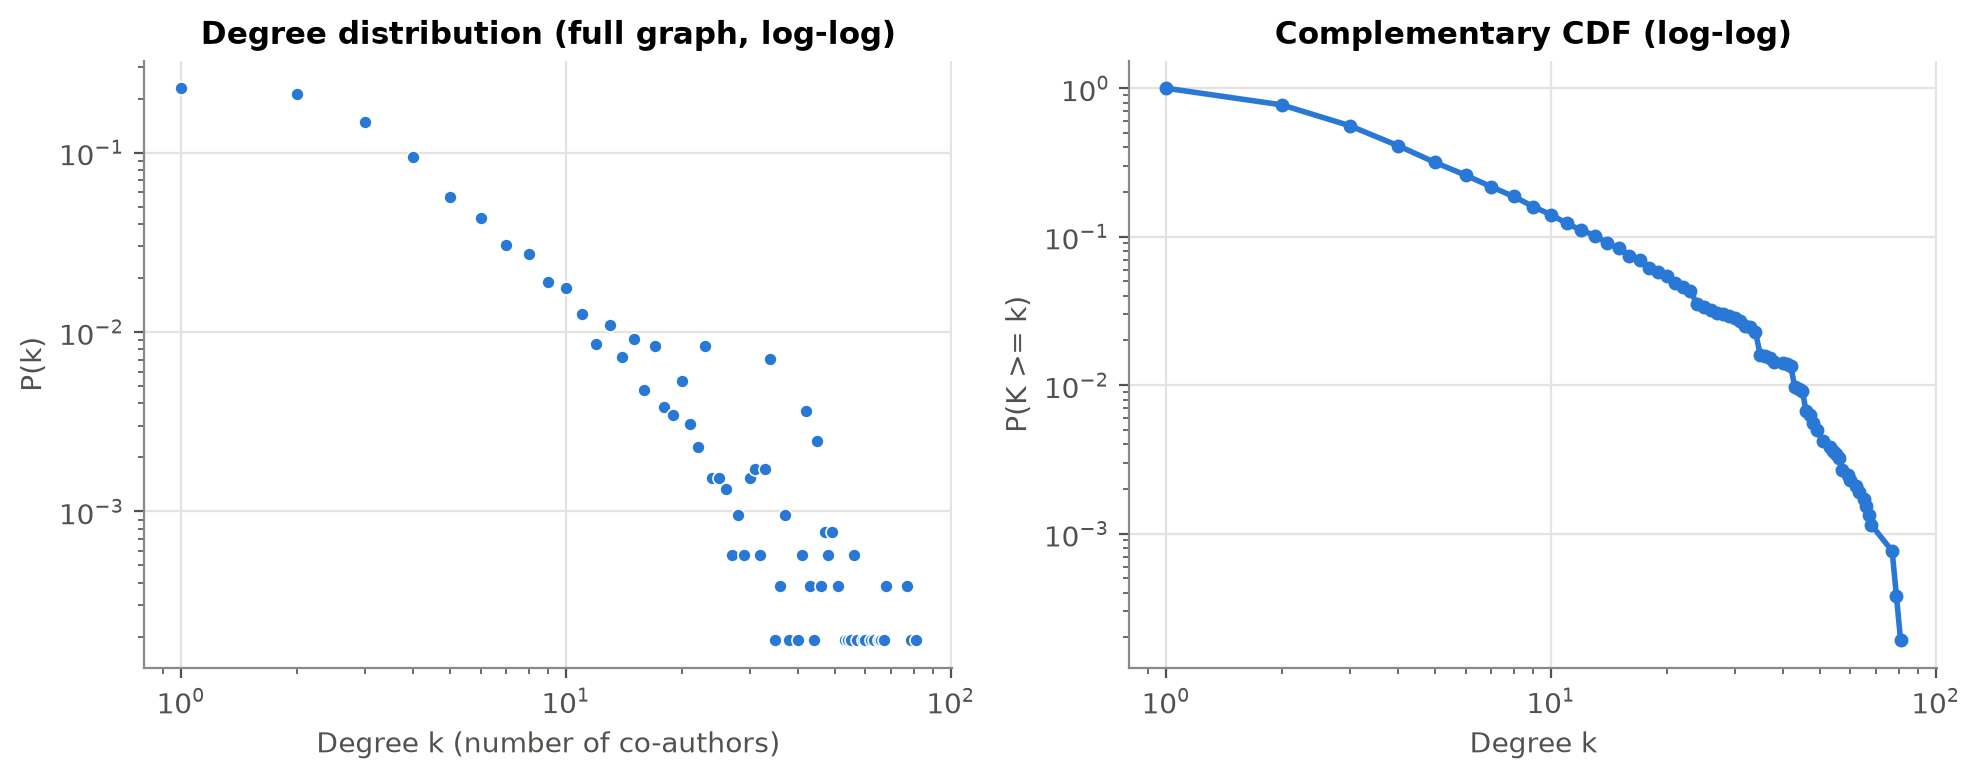

In [4]:
# Degree distribution (log-log): a heavy tail = a few highly collaborative authors
deg_dist = data.degree_distribution(G)
deg_dist.to_csv(OUTPUT_DIR / "degree_distribution.csv", index=False)
viz.save_fig(viz.plot_degree_distribution(G, " (full graph, log-log)"), "fig_degree_distribution")
display(Image(VIZ_DIR / "fig_degree_distribution.png", width=850))

In [5]:
# Central authors: degree, betweenness (exact, on the full graph) and PageRank
t = time.time()
cent = data.centrality_table(G, betweenness_k=None)
print(f"centrality computed in {time.time() - t:.1f} s (exact betweenness)")
top10 = {c: data.top_k_by(cent, c, 10)[["node", "degree", "betweenness", "pagerank"]]
         for c in ("degree", "betweenness", "pagerank")}
RESULTS["top10_authors"] = {c: df.to_dict("records") for c, df in top10.items()}
side = pd.concat({f"Top by {c}": df.set_index(df.index + 1) for c, df in top10.items()}, axis=1)
side.to_csv(OUTPUT_DIR / "top10_central_authors.csv")
overlap = set(top10["degree"].node) & set(top10["betweenness"].node) & set(top10["pagerank"].node)
RESULTS["top10_overlap_all_three"] = sorted(overlap)
print("Authors in all three top-10 lists:", sorted(overlap))
side

centrality computed in 105.9 s (exact betweenness)
Authors in all three top-10 lists: []


Top by degree                              Top by betweenness                              Top by pagerank                             
            node degree betweenness  pagerank               node degree betweenness  pagerank            node degree betweenness  pagerank
1          21012     81    0.011649  0.001070              13801     45    0.037027  0.001343           14265     37    0.019731  0.001449
2          21281     79    0.009643  0.001153               9572     34    0.025689  0.001173           13801     45    0.037027  0.001343
3          12365     77    0.011229  0.001035              14599     30    0.025488  0.000908           13929     45    0.024653  0.001306
4          22691     77    0.009777  0.001082               7689     32    0.024971  0.001096            9572     34    0.025689  0.001173
5           6610     68    0.012767  0.000909              13929     45    0.024653  0.001306            2710     33    0.022355  0.001153
6           9785     68    0.007255  0.000809               5052     29    0.024422  0.000951           21281     79    0.009643  0.001153
7          21508     67    0.003228  0.000824              14485     21    0.023503  0.000616            7689     32    0.024971  0.001096
8          17655     66    0.017999  0.000897               2710     33    0.022355  0.001153           22691     77    0.009777  0.001082
9           2741     65    0.005866  0.000774              14265     37    0.019731  0.001449            6264     32    0.009982  0.001072
10         19423     63    0.007095  0.000844              17655     66    0.017999  0.000897           21012     81    0.011649  0.001070

**Reading the statistics.** The graph is very sparse (density close to 0) but strongly
clustered (clustering coefficient far above the density), split into many small components
with one giant component, and degree-assortative (well-connected authors collaborate with
each other). The degree distribution is heavy-tailed. High clustering is exactly the
property that neighbourhood-based link predictors exploit: *two authors who share
co-authors tend to become co-authors themselves* (triadic closure).

The three centrality rankings highlight different roles: **degree** finds the most
prolific collaborators (often members of very large multi-author papers), **betweenness**
finds the brokers that connect otherwise separate groups, and **PageRank** finds authors
connected to other well-connected authors.

---
## Phase 2 - Data Preparation & Network Construction

### 2.1 Cleaning (done above in `data.clean_edges`)
1. Comment lines (`#`) skipped.
2. **Self-loops removed** - an author cannot co-author with themself.
3. **Direction removed** - SNAP stores each undirected pair twice (u→v and v→u); pairs are put in
   canonical order (min, max) and **duplicates dropped**.
4. Every author ID in the file is kept as a node.

### 2.2 80/20 edge split that keeps the training graph connected
We work on the LCC. Naively deleting 20 % of edges at random would cut bridges and isolate
low-degree authors, who could then never be predicted. Instead:

1. Draw a **random spanning tree** of the LCC (minimum spanning tree over random edge weights, seed 42).
   A spanning tree contains every bridge, so keeping it guarantees the training graph stays
   connected and every node keeps degree ≥ 1.
2. Sample the 20 % **test positives** uniformly (seed 42) from the remaining *non-tree* edges.
3. The training graph = all LCC nodes + the other 80 % of edges.

### 2.3 Negative sampling and leakage
A ranking metric needs examples of pairs that do **not** link. We sample author pairs
uniformly at random that are **not edges of the full graph** (otherwise a hidden test edge
could be mislabelled as a negative), 1:1 with the positives, for both the training pairs
and the test pairs (disjoint sets).

**Leakage.** All scores are computed **only on the training graph**. If the test edges were
present while scoring, every test pair would trivially look connected and the evaluation
would be meaningless. Training positives *are* edges of the training graph, so when they are
scored their own edge is hidden (otherwise PA/Jaccard would see the very edge they should predict).

In [6]:
split = data.build_pair_sets(L, seed=SEED, test_frac=0.2)
G_train = split["G_train"]

# Sanity checks - the notebook stops here if any of them fails
assert set(G_train.nodes()) == set(L.nodes()), "train graph lost nodes"
assert nx.is_connected(G_train), "train graph is disconnected"
assert nx.number_of_isolates(G_train) == 0
assert not any(G_train.has_edge(u, v) for u, v in split["test_pos"]), "test edge leaked into train graph"
assert all(not G.has_edge(u, v) for u, v in split["train_neg"] + split["test_neg"]), "negative is a real edge"
assert not set(split["train_neg"]) & set(split["test_neg"]), "train/test negatives overlap"

split_info = {
    "seed": SEED, "lcc_nodes": L.number_of_nodes(), "lcc_edges": L.number_of_edges(),
    "forest_edges": L.number_of_nodes() - nx.number_connected_components(L),
    "n_train_pos": len(split["train_pos"]), "n_test_pos": len(split["test_pos"]),
    "n_train_neg": len(split["train_neg"]), "n_test_neg": len(split["test_neg"]),
    "train_graph_nodes": G_train.number_of_nodes(), "train_graph_edges": G_train.number_of_edges(),
    "train_components": nx.number_connected_components(G_train),
    "train_avg_clustering": nx.average_clustering(G_train),
}
RESULTS["split"] = split_info
pd.Series(split_info, name="value").to_frame()

,value
seed,42.000000
lcc_nodes,4158.000000
lcc_edges,13422.000000
forest_edges,4157.000000
n_train_pos,10738.000000
n_test_pos,2684.000000
n_train_neg,10738.000000
n_test_neg,2684.000000
train_graph_nodes,4158.000000
train_graph_edges,10738.000000


In [7]:
# Save the processed dataset package to /dataset
train_deg = dict(G_train.degree())
nodes_df = cent.copy()
nodes_df["in_lcc"] = nodes_df.node.isin(set(L.nodes()))
nodes_df["train_degree"] = nodes_df.node.map(train_deg).astype("Int64")
nodes_df = nodes_df[["node", "degree", "in_lcc", "train_degree", "degree_centrality", "betweenness", "pagerank"]]
dataset_files = data.save_dataset_package(clean_df, split, nodes_df)
data.write_dataset_readme(clean_log, split_info)

zip_path = DATASET_DIR / "dataset.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(DATASET_DIR.rglob("*")):
        if p.is_file() and p != zip_path:
            z.write(p, p.relative_to(DATASET_DIR))
RESULTS["dataset_files"] = {**dataset_files, "readme": "dataset/README.md", "zip": "dataset/dataset.zip"}
display(pd.read_csv(DATASET_DIR / "test_edges.csv").groupby("label").size().rename("test pairs"))
sorted(p.name for p in DATASET_DIR.iterdir())

label
0    2684
1    2684
Name: test pairs, dtype: int64

['README.md',
 'ca-GrQc_clean_edges.csv',
 'dataset.zip',
 'nodes.csv',
 'raw',
 'test_edges.csv',
 'train_edges.csv',
 'train_graph_edges.csv']

---
## Phase 3 - Link Prediction Heuristics

Notation: $\Gamma(x)$ = set of co-authors (neighbours) of author $x$, $k(x)=|\Gamma(x)|$ = degree.
All four are implemented from scratch with Python sets in `src/scores.py`.

**1. Common Neighbours (CN)** - how many collaborators the two authors share (triadic closure).
$$CN(u,v)=|\Gamma(u)\cap\Gamma(v)|$$

**2. Jaccard Coefficient (JC)** - shared collaborators as a fraction of all their collaborators;
normalises CN so that prolific authors are not automatically favoured.
$$JC(u,v)=\frac{|\Gamma(u)\cap\Gamma(v)|}{|\Gamma(u)\cup\Gamma(v)|}$$

**3. Adamic-Adar (AA)** - like CN, but each shared collaborator $w$ is weighted by $1/\log k(w)$:
a shared collaborator who works with very few people is strong evidence, a hub who works with
everyone is weak evidence.
$$AA(u,v)=\sum_{w\in\Gamma(u)\cap\Gamma(v)}\frac{1}{\log k(w)}$$

**4. Preferential Attachment (PA)** - "the rich get richer": the probability of a new edge
grows with the product of the degrees; it ignores whether the authors are close in the network.
$$PA(u,v)=k(u)\cdot k(v)$$

CN, JC and AA are *local* similarity indices (they need a shared neighbour, i.e. distance 2);
PA is a *global popularity* index.

In [8]:
nbrs_train = scores.neighbour_sets(G_train)
t = time.time()
train_scored = scores.score_labelled(G_train, split["train_pairs"], nbrs_train)
test_scored = scores.score_labelled(G_train, split["test_pairs"], nbrs_train)
print(f"scored {len(train_scored) + len(test_scored):,} pairs in {time.time() - t:.2f} s")

# Cross-check our implementation against NetworkX on every test pair and every train negative
check_pairs = split["test_pos"] + split["test_neg"] + split["train_neg"]
diff = scores.cross_check(G_train, check_pairs)
RESULTS["cross_check_max_abs_diff"] = diff
RESULTS["cross_check_pairs"] = len(check_pairs)
assert max(diff.values()) < 1e-9, diff
print(f"max |ours - networkx| over {len(check_pairs):,} pairs:", diff)

train_scored.to_csv(OUTPUT_DIR / "train_pairs_scored.csv", index=False)
test_scored.to_csv(OUTPUT_DIR / "test_pairs_scored.csv", index=False)
test_scored.sample(8, random_state=SEED)

scored 26,844 pairs in 0.30 s


max |ours - networkx| over 16,106 pairs: {'cn': 0.0, 'jaccard': 0.0, 'adamic_adar': 0.0, 'pref_attach': 0.0}


,u,v,label,cn,jaccard,adamic_adar,pref_attach
410,2212,20108,1,25,0.595238,6.798255,1116
3625,5251,20432,0,0,0.000000,0.000000,16
838,4351,8968,1,0,0.000000,0.000000,36
4080,3119,14123,0,0,0.000000,0.000000,18
4572,17339,19909,0,0,0.000000,0.000000,2
642,3372,12496,1,26,0.553191,7.025872,1332
4336,1105,16953,0,0,0.000000,0.000000,2
1539,9124,20886,1,1,0.050000,0.345976,20


In [9]:
# Average score of positives vs negatives on the test set, and how many pairs have no shared co-author
means = test_scored.groupby("label")[list(METHODS)].mean().rename(index={0: "negatives", 1: "positives"})
zero_cn = test_scored.groupby("label")["cn"].apply(lambda s: float((s == 0).mean()))
RESULTS["test_score_means"] = means.to_dict("index")
RESULTS["test_zero_cn_fraction"] = {"negatives": zero_cn[0], "positives": zero_cn[1]}
display(means.rename(columns=METHODS))
print(f"test positives with no common neighbour: {zero_cn[1]:.1%};  negatives: {zero_cn[0]:.1%}")

,Common Neighbours,Jaccard,Adamic-Adar,Preferential Attachment
label,,,,
negatives,0.005589,0.000409,0.002108,24.458644
positives,7.582340,0.327547,2.598673,337.516766


test positives with no common neighbour: 8.8%;  negatives: 99.6%


---
## Phase 4 - Algorithm Comparison & Validation

* **ROC-AUC** - probability that a random positive pair is scored above a random negative pair
  (threshold-free, uses the whole ranking).
* **Average Precision (AP)** - area under the precision-recall curve.
* **Precision@K** - all candidate pairs ranked by score; fraction of true links among the top K
  (K = 10, 20, 50, 100). Ties are broken randomly with seed 42.
* **Precision / Recall / F1 at a threshold** - the threshold is chosen to **maximise F1 on the
  training pairs** (never on the test set) and then applied unchanged to the test pairs.

In [10]:
metrics = evaluate.evaluate_all(train_scored, test_scored)
metrics.to_csv(OUTPUT_DIR / "metrics_test.csv")
RESULTS["metrics_test"] = metrics.drop(columns="method").to_dict("index")
show = metrics.copy()
show.columns = ["Method", "ROC-AUC", "AP", "Threshold (from train)", "Train F1 @ thr",
                "Precision", "Recall", "F1", "P@10", "P@20", "P@50", "P@100"]
show.set_index("Method").round(4)

,ROC-AUC,AP,Threshold (from train),Train F1 @ thr,Precision,Recall,F1,P@10,P@20,P@50,P@100
Method,,,,,,,,,,,
Common Neighbours,0.9554,0.9550,1.0000,0.8885,0.9951,0.9124,0.9520,1.0,1.0,1.0,1.0
Jaccard,0.9555,0.9555,0.0119,0.8885,0.9951,0.9124,0.9520,1.0,1.0,1.0,1.0
Adamic-Adar,0.9557,0.9558,0.2423,0.8885,0.9951,0.9124,0.9520,1.0,1.0,1.0,1.0
Preferential Attachment,0.8490,0.8662,10.0000,0.6692,0.6516,0.9016,0.7565,1.0,1.0,1.0,1.0


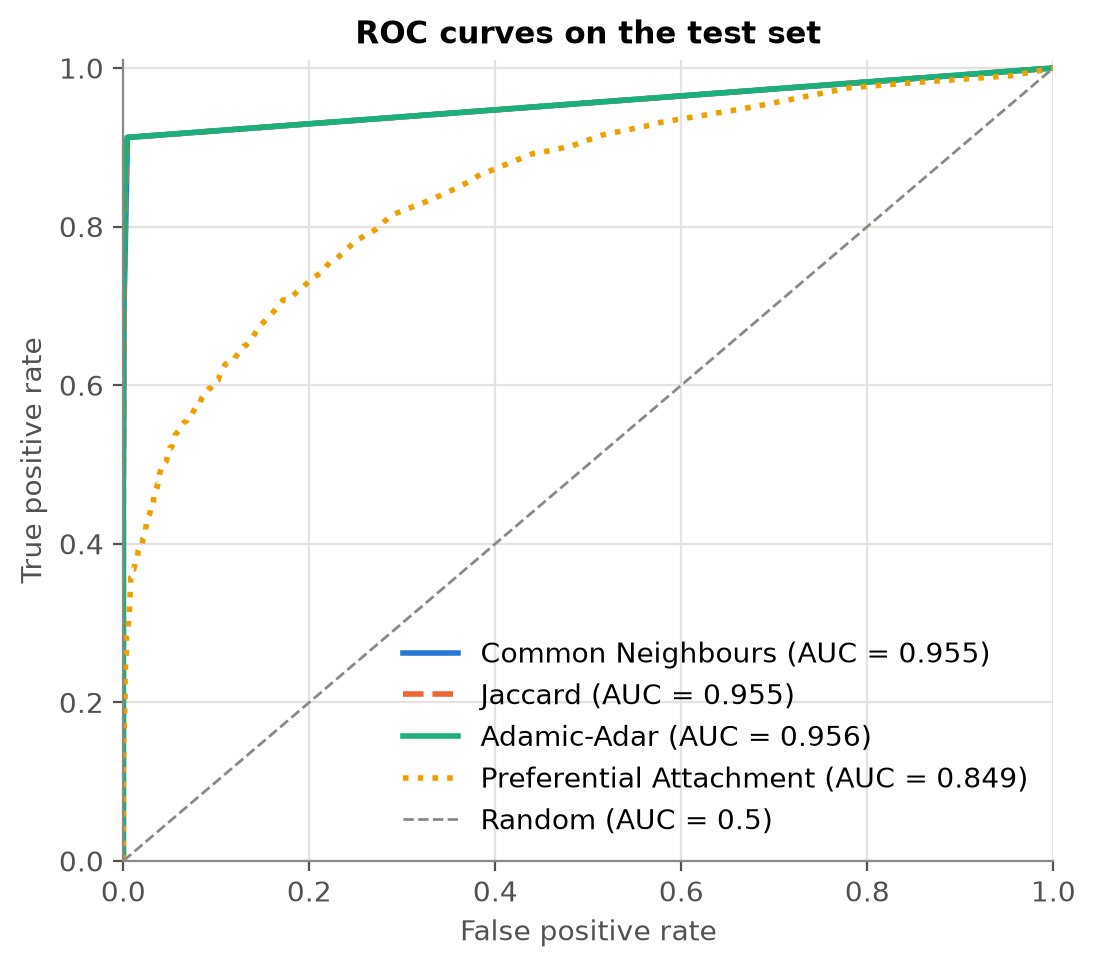

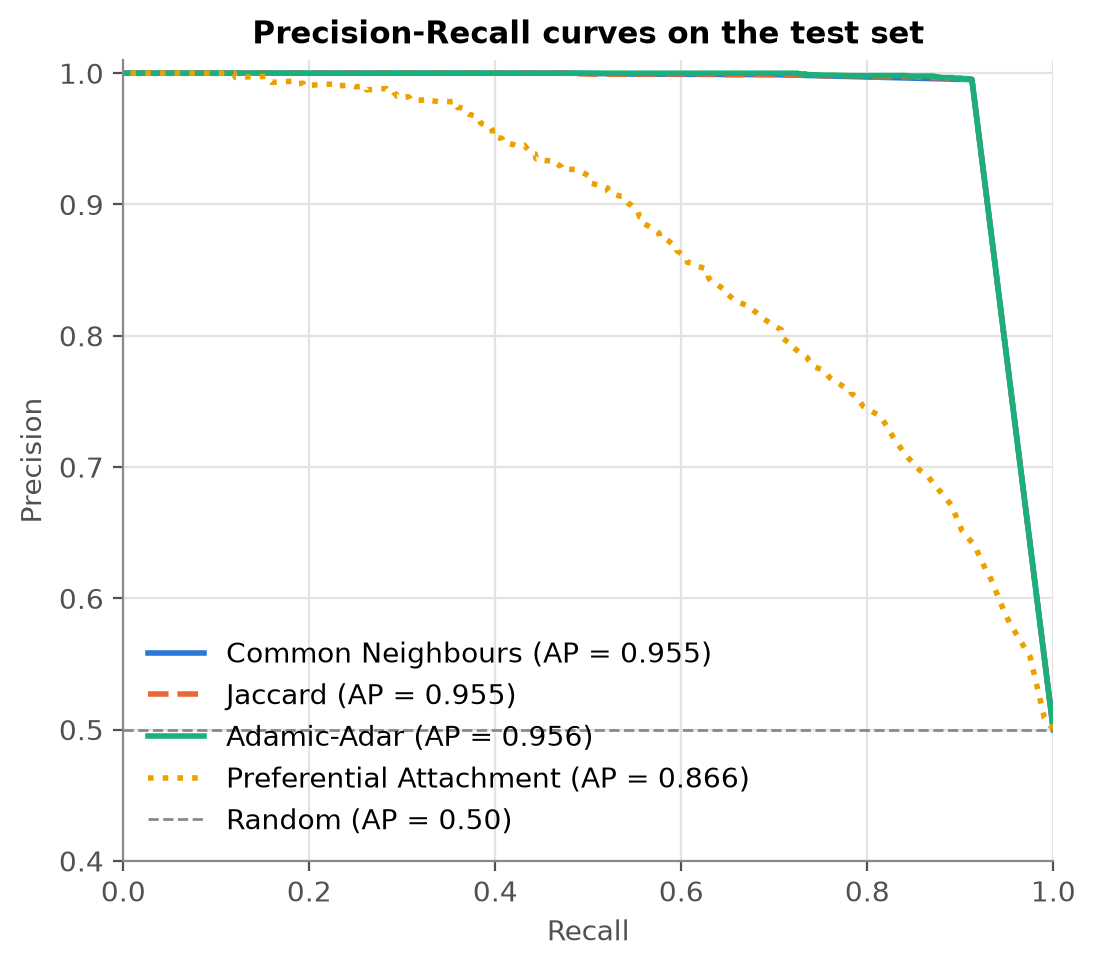

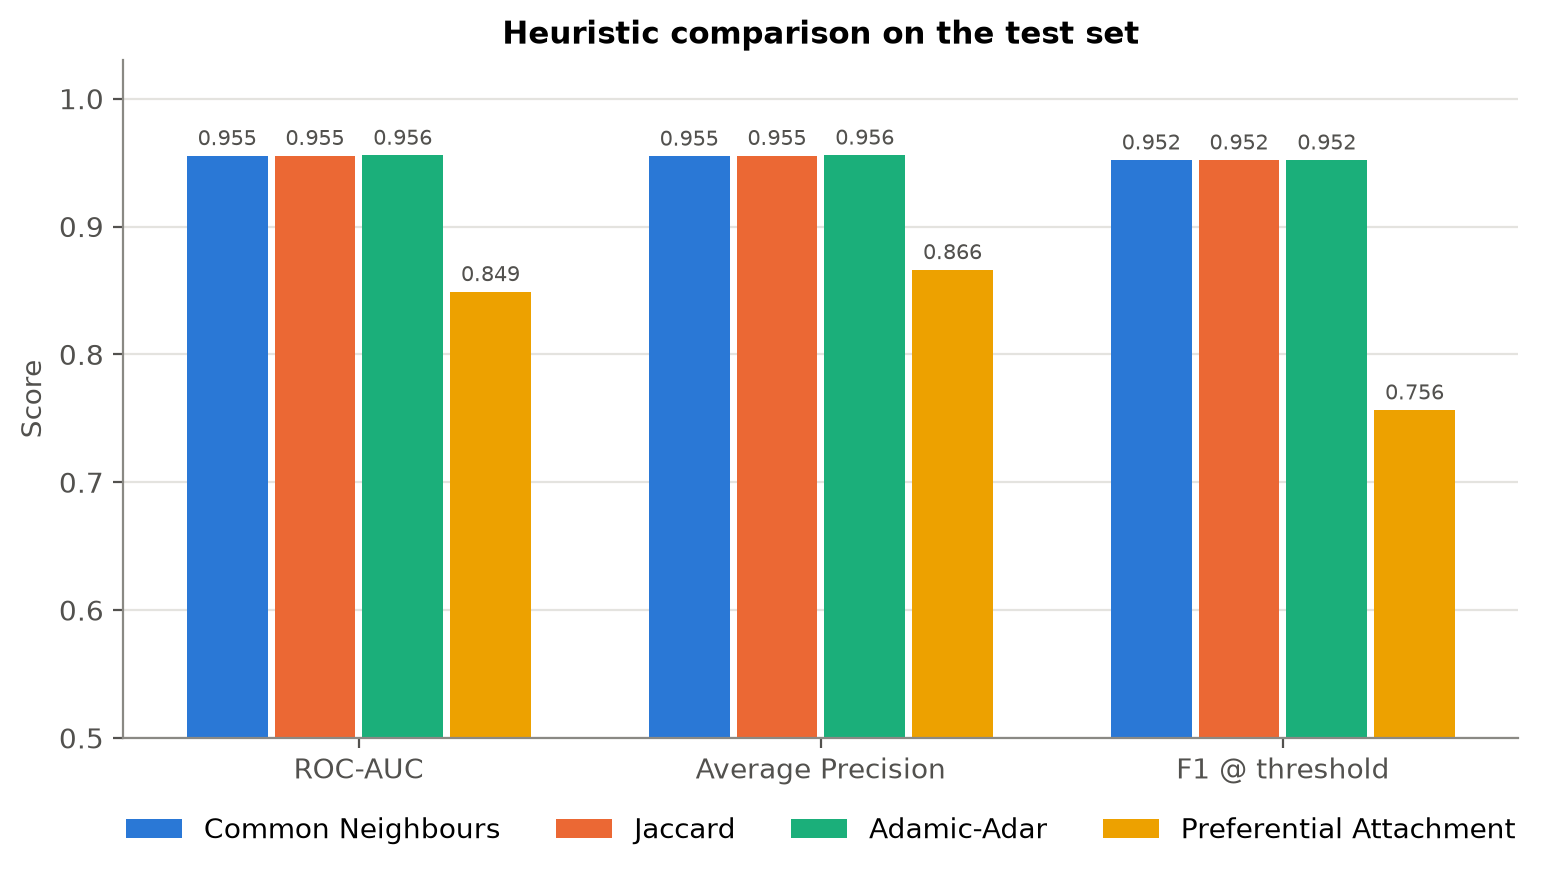

In [11]:
curves = evaluate.curves(test_scored)
viz.save_fig(viz.plot_roc(curves, metrics), "fig_roc_curves")
viz.save_fig(viz.plot_pr(curves, metrics, base_rate=test_scored.label.mean()), "fig_pr_curves")
viz.save_fig(viz.plot_metric_bars(metrics), "fig_metric_comparison")
for f in ("fig_roc_curves", "fig_pr_curves", "fig_metric_comparison"):
    display(Image(VIZ_DIR / f"{f}.png", width=620))

### 4.1 A harder test: negatives that share a collaborator
With uniformly random negatives almost every negative pair has **no** common neighbour, so
Precision@K saturates at 1.0 for small K. To separate the methods more sharply we build a second
test set with the same positives but **hard negatives**: non-edges of the full graph that are at
distance exactly 2 in the training graph (they already share at least one collaborator).

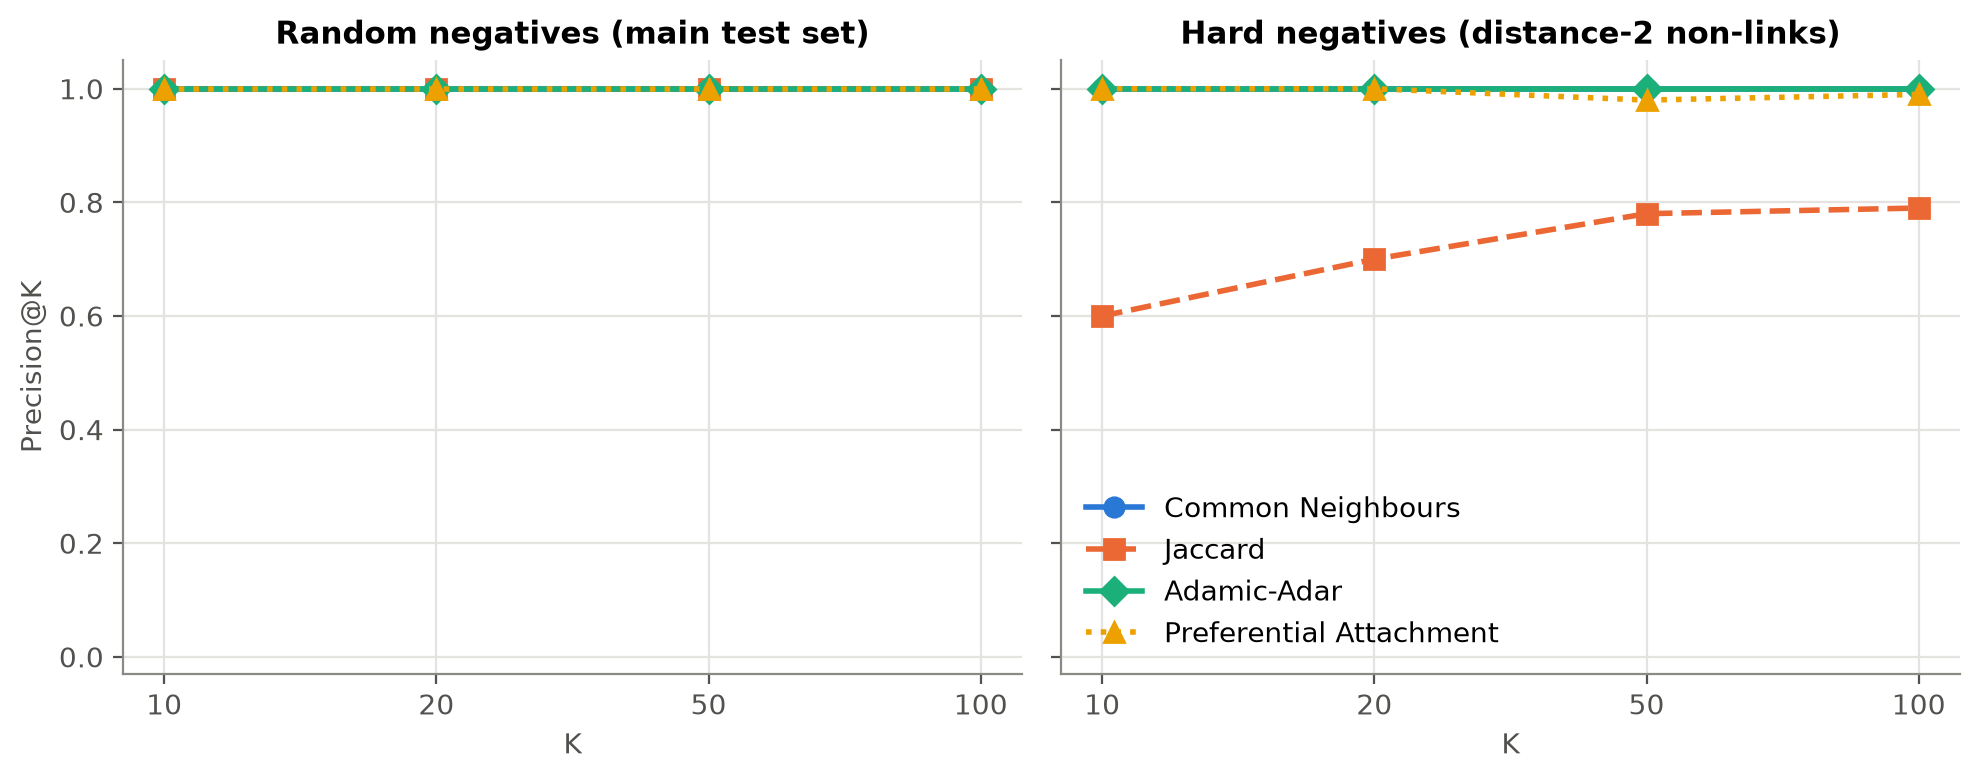

,roc_auc,average_precision,f1,p@10,p@20,p@50,p@100
method,,,,,,,
Common Neighbours,0.7776,0.8144,0.6266,1.0,1.0,1.00,1.00
Jaccard,0.7594,0.7880,0.6267,0.6,0.7,0.78,0.79
Adamic-Adar,0.8504,0.9004,0.6266,1.0,1.0,1.00,1.00
Preferential Attachment,0.6438,0.6812,0.6623,1.0,1.0,0.98,0.99


In [12]:
hard_neg = data.sample_hard_negatives(L, G_train, len(split["test_pos"]), np.random.default_rng(SEED),
                                      exclude=set(split["train_neg"]) | set(split["test_neg"]))
hard_pairs = pd.DataFrame(split["test_pos"] + hard_neg, columns=["u", "v"])
hard_pairs["label"] = [1] * len(split["test_pos"]) + [0] * len(hard_neg)
hard_scored = scores.score_labelled(G_train, hard_pairs, nbrs_train)
hard_metrics = evaluate.evaluate_all(train_scored, hard_scored)
hard_metrics.to_csv(OUTPUT_DIR / "metrics_hard_negatives.csv")
RESULTS["metrics_hard_negatives"] = hard_metrics.drop(columns="method").to_dict("index")
RESULTS["n_hard_negatives"] = len(hard_neg)

pk_cols = [f"p@{k}" for k in evaluate.K_VALUES]
pk_panels = {"Random negatives (main test set)": metrics[pk_cols].set_axis(evaluate.K_VALUES, axis=1),
             "Hard negatives (distance-2 non-links)": hard_metrics[pk_cols].set_axis(evaluate.K_VALUES, axis=1)}
viz.save_fig(viz.plot_precision_at_k(pk_panels), "fig_precision_at_k")
display(Image(VIZ_DIR / "fig_precision_at_k.png", width=850))
hard_metrics.set_index("method")[["roc_auc", "average_precision", "f1", *pk_cols]].round(4)

### 4.2 Stability over 5 random splits
The whole pipeline (spanning-tree split → negative sampling → scoring → ROC-AUC) is repeated
for seeds 42, 43, 44, 45, 46.

5 splits in 3.4 s


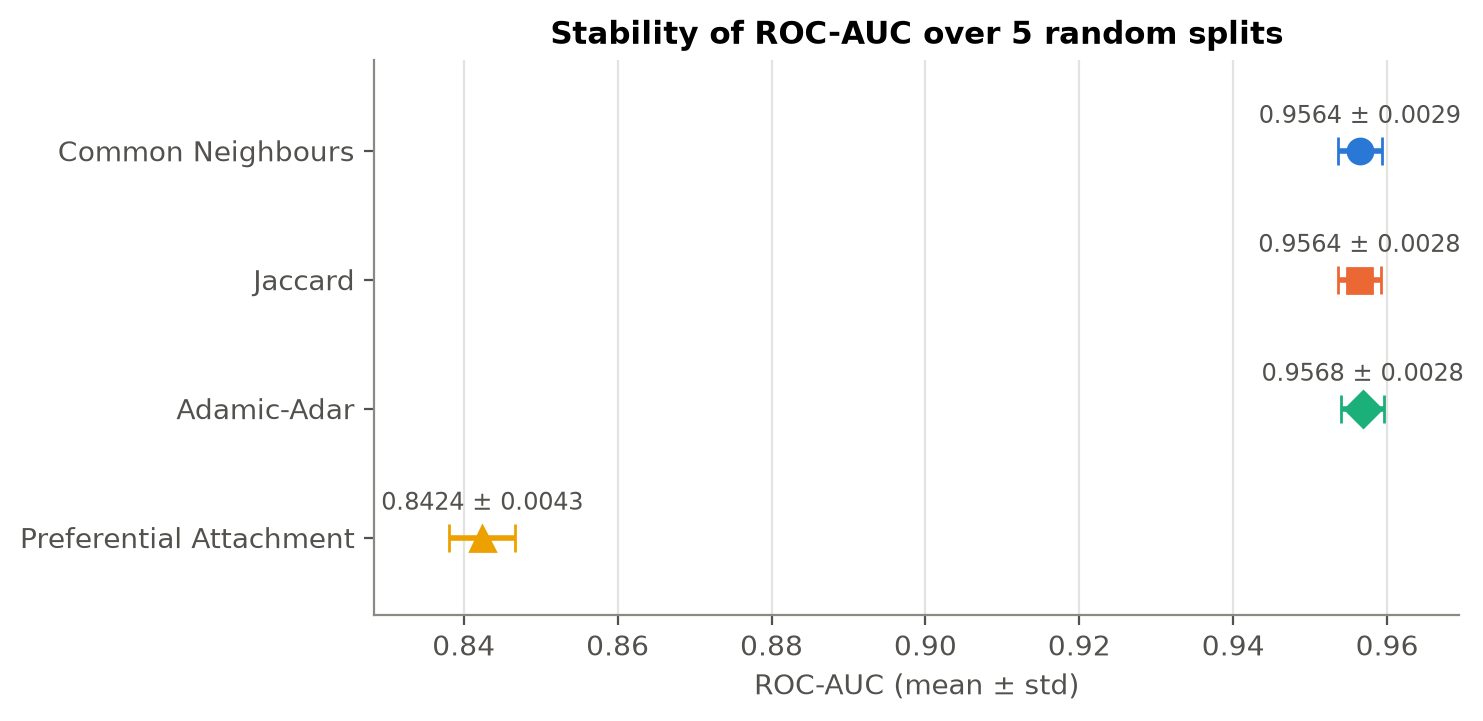

,name,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
method,,,,,
cn,Common Neighbours,0.9564,0.0029,0.9560,0.0028
jaccard,Jaccard,0.9564,0.0028,0.9560,0.0023
adamic_adar,Adamic-Adar,0.9568,0.0028,0.9569,0.0028
pref_attach,Preferential Attachment,0.8424,0.0043,0.8614,0.0034


In [13]:
t = time.time()
seed_runs = evaluate.multi_seed_auc(L, seeds=(42, 43, 44, 45, 46))
seed_summary = evaluate.summarise_seeds(seed_runs)
print(f"5 splits in {time.time() - t:.1f} s")
seed_runs.to_csv(OUTPUT_DIR / "multi_seed_runs.csv", index=False)
seed_summary.to_csv(OUTPUT_DIR / "multi_seed_summary.csv")
RESULTS["multi_seed"] = {"seeds": [42, 43, 44, 45, 46],
                         "runs": seed_runs.to_dict("records"),
                         "summary": seed_summary.drop(columns="name").to_dict("index")}
viz.save_fig(viz.plot_seed_stability(seed_summary, 5), "fig_seed_stability")
display(Image(VIZ_DIR / "fig_seed_stability.png", width=650))
seed_summary.round(4)

In [14]:
# Pick the best method: highest mean ROC-AUC over the 5 splits, ties broken by hard-negative AP
rank_df = pd.DataFrame({"auc_mean": seed_summary["roc_auc_mean"],
                        "hard_ap": hard_metrics["average_precision"].astype(float)})
best = rank_df.sort_values(["auc_mean", "hard_ap"], ascending=False).index[0]
RESULTS["best_method"] = {"key": best, "name": METHODS[best]}

m, h, s = metrics.astype({"roc_auc": float}), hard_metrics, seed_summary
local = ["cn", "jaccard", "adamic_adar"]
text = f'''**Best method: {METHODS[best]}** (mean ROC-AUC over 5 splits = {s.loc[best, "roc_auc_mean"]:.4f} ± {s.loc[best, "roc_auc_std"]:.4f}).

* On the main test set the three local indices are almost tied
  (ROC-AUC {m.loc[local, "roc_auc"].min():.4f} - {m.loc[local, "roc_auc"].max():.4f}), and far ahead of
  Preferential Attachment ({m.loc["pref_attach", "roc_auc"]:.4f}).
* With **hard negatives** the gap opens: Adamic-Adar ROC-AUC = {float(h.loc["adamic_adar", "roc_auc"]):.4f},
  CN = {float(h.loc["cn", "roc_auc"]):.4f}, Jaccard = {float(h.loc["jaccard", "roc_auc"]):.4f},
  PA = {float(h.loc["pref_attach", "roc_auc"]):.4f}.
* Thresholds learned on the training pairs: CN >= {m.loc["cn", "threshold"]:.0f}, Jaccard >= {m.loc["jaccard", "threshold"]:.4f},
  AA >= {m.loc["adamic_adar", "threshold"]:.4f} - all three amount to "at least one shared co-author", hence identical
  test P/R/F1 = {m.loc["adamic_adar", "precision"]:.3f}/{m.loc["adamic_adar", "recall"]:.3f}/{m.loc["adamic_adar", "f1"]:.3f};
  PA >= {m.loc["pref_attach", "threshold"]:.0f} (test F1 = {m.loc["pref_attach", "f1"]:.3f}).
'''
RESULTS["phase4_summary_md"] = text
display(Markdown(text))

**Best method: Adamic-Adar** (mean ROC-AUC over 5 splits = 0.9568 ± 0.0028).

* On the main test set the three local indices are almost tied
  (ROC-AUC 0.9554 - 0.9557), and far ahead of
  Preferential Attachment (0.8490).
* With **hard negatives** the gap opens: Adamic-Adar ROC-AUC = 0.8504,
  CN = 0.7776, Jaccard = 0.7594,
  PA = 0.6438.
* Thresholds learned on the training pairs: CN >= 1, Jaccard >= 0.0119,
  AA >= 0.2423 - all three amount to "at least one shared co-author", hence identical
  test P/R/F1 = 0.995/0.912/0.952;
  PA >= 10 (test F1 = 0.756).


**Why this ranking?**
* ca-GrQc is dominated by **triadic closure**: authors join papers as groups, so collaborators of
  collaborators very often become collaborators. Every local index captures this, which is why CN,
  Jaccard and AA all reach high ROC-AUC, while most random negatives share nobody.
* **Adamic-Adar** wins on the harder comparison because it discounts shared *hubs*. Two authors who
  both worked with a 60-co-author hub tell us little; two authors who share a collaborator with only
  3 co-authors almost certainly belong to the same small team.
* **Jaccard** divides by the union of the neighbourhoods, which over-rewards pairs of low-degree
  authors (two authors with 2 co-authors each sharing 1 gets 0.33) and penalises members of large
  groups.
* **Preferential Attachment** only looks at degrees. Hubs in this graph are members of large
  multi-author papers, so PA keeps proposing hub-hub pairs from *different* groups that are far
  apart - it misses the strong locality of collaboration. It still beats random because the network is
  degree-assortative.

---
## Phase 5 - Recommendation & Interpretation

**Candidate pairs.** Scoring all $\binom{n}{2}$ ≈ 8.6 million LCC pairs is unnecessary: for CN, Jaccard
and Adamic-Adar every pair at distance ≥ 3 has **no** common neighbour and scores exactly 0, so it can
never reach a Top-K list. We therefore restrict candidates to non-adjacent pairs at distance exactly 2
(they share at least one co-author). For PA this is a deliberate restriction - it stops PA from
recommending pairs of hubs that have no connection at all.

**Filters.** No self-pairs, no pair already linked in the full graph, no duplicate (u, v)/(v, u)
(candidates are canonical u < v).

### 5.1 Validation: do Top-K predictions from the training graph come true?
Rank every distance-2 candidate of the **training graph** and count how many of the Top-K are held-out
test edges (hit rate = precision@K over the realistic candidate pool).

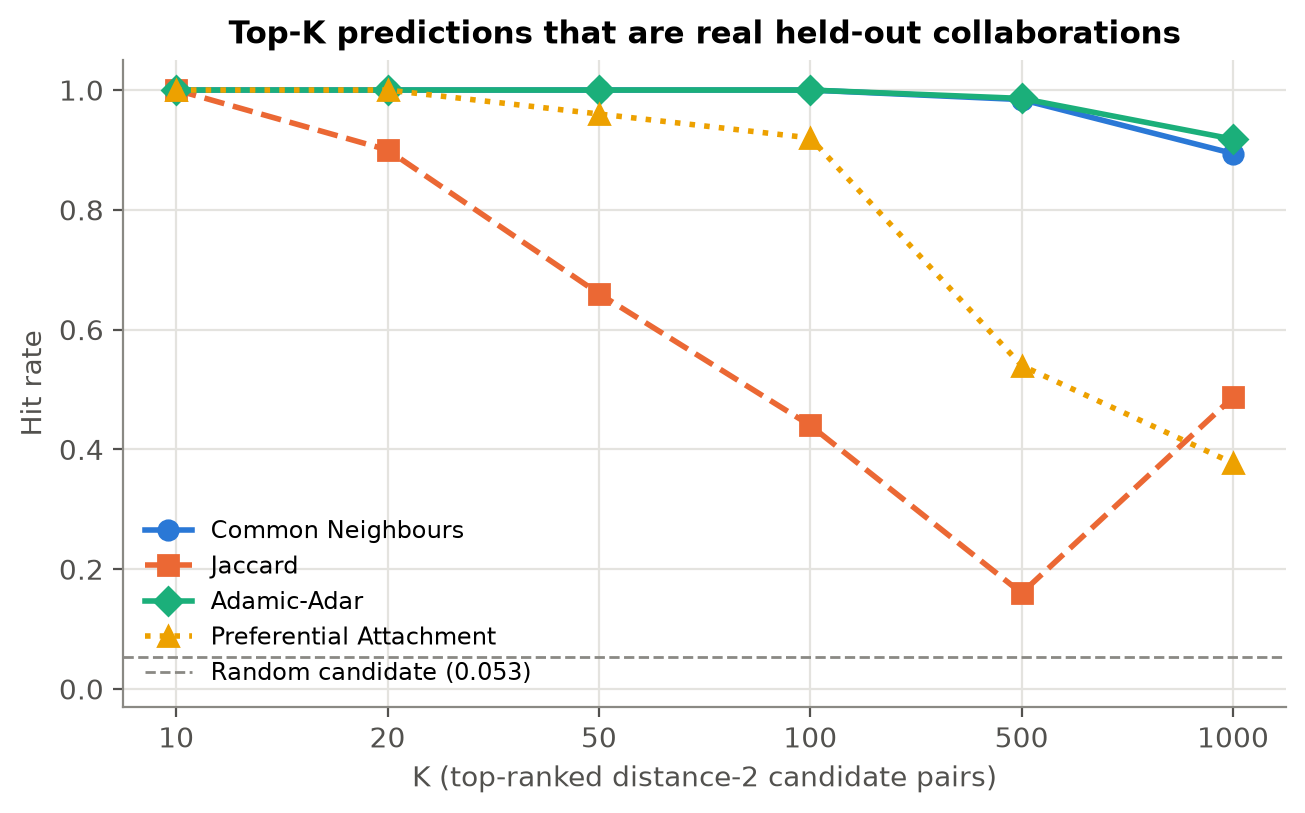

,value
n_candidates,46588.000000
n_test_positives,2684.000000
n_test_in_candidates,2449.000000
share_test_at_distance_2,0.912444
random_baseline_hit_rate,0.052567


method,Adamic-Adar,Common Neighbours,Jaccard,Preferential Attachment
k,,,,
10,1.000,1.000,1.000,1.000
20,1.000,1.000,0.900,1.000
50,1.000,1.000,0.660,0.960
100,1.000,1.000,0.440,0.920
500,0.986,0.984,0.160,0.540
1000,0.918,0.894,0.487,0.377


In [15]:
hits, pool = recommend.hit_rate(G_train, split["test_pos"], ks=(10, 20, 50, 100, 500, 1000), nbrs=nbrs_train)
hits.to_csv(OUTPUT_DIR / "hit_rate.csv", index=False)
RESULTS["hit_rate"] = hits.to_dict("records")
RESULTS["candidate_pool_train"] = pool
viz.save_fig(viz.plot_hit_rate(hits, pool["random_baseline_hit_rate"]), "fig_hit_rate")
display(Image(VIZ_DIR / "fig_hit_rate.png", width=700))
display(pd.Series(pool, name="value").to_frame())
hits.pivot(index="k", columns="method", values="hit_rate").rename(columns=METHODS)

### 5.2 Recommendations for the future (full LCC as observed)
For actual recommendations we use **all** observed collaborations (the full LCC), so the
predictions are links that do not exist anywhere in the data.

In [16]:
nbrs_full = scores.neighbour_sets(L)
cands_full = recommend.distance2_candidates(L, nbrs_full)
RESULTS["candidate_pool_full"] = {"n_candidates": len(cands_full), "graph": "LCC"}
print(f"{len(cands_full):,} distance-2 candidate pairs in the LCC")

top20 = recommend.recommend(L, best, 20, cands_full, nbrs_full, exclude=G)
top10 = pd.concat([recommend.recommend(L, m, 10, cands_full, nbrs_full, exclude=G) for m in METHODS],
                  ignore_index=True)

# Filter checks
for df in (top20, top10):
    assert (df.author_u != df.author_v).all()
    assert not any(G.has_edge(u, v) for u, v in zip(df.author_u, df.author_v))
    assert not df.duplicated(["method", "author_u", "author_v"]).any()

top20.to_csv(OUTPUT_DIR / "top20_recommendations.csv", index=False)
top10.to_csv(OUTPUT_DIR / "top10_recommendations.csv", index=False)
RESULTS["top20"] = top20.to_dict("records")
RESULTS["top10"] = top10.to_dict("records")
print(f"Top-20 recommendations - {METHODS[best]}")
top20.drop(columns=["method", "explanation"])

63,288 distance-2 candidate pairs in the LCC


Top-20 recommendations - Adamic-Adar


,rank,author_u,author_v,score,common_neighbours,shortest_path,degree_u,degree_v,shared_collaborators
0,1,45,46,10.597803,42,2,49,42,"2952 (deg 45), 4511 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 ..."
1,2,4511,4513,10.592055,42,2,45,43,"2952 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 (deg 45), 12851..."
2,3,4511,22691,10.592055,42,2,45,77,"2952 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 (deg 45), 12851..."
3,4,46,4513,10.335106,41,2,42,43,"2952 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 (deg 45), 12851..."
4,5,46,22691,10.335106,41,2,42,77,"2952 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 (deg 45), 12851..."
5,6,5210,7444,6.699083,25,2,33,28,"15457 (deg 34), 23712 (deg 34), 20574 (deg 37), 24718 (deg 40), 88..."
6,7,7444,8727,6.699083,25,2,28,33,"15457 (deg 34), 23712 (deg 34), 20574 (deg 37), 24718 (deg 40), 88..."
7,8,7444,9869,6.699083,25,2,28,41,"15457 (deg 34), 23712 (deg 34), 20574 (deg 37), 24718 (deg 40), 88..."
8,9,7444,12710,6.699083,25,2,28,33,"15457 (deg 34), 23712 (deg 34), 20574 (deg 37), 24718 (deg 40), 88..."
9,10,7444,15245,6.699083,25,2,28,33,"15457 (deg 34), 23712 (deg 34), 20574 (deg 37), 24718 (deg 40), 88..."


In [17]:
for m in METHODS:
    if m == best:
        continue
    print(f"Top-10 - {METHODS[m]}")
    display(top10[top10.method == METHODS[m]].drop(columns=["method", "explanation"]))

Top-10 - Common Neighbours


,rank,author_u,author_v,score,common_neighbours,shortest_path,degree_u,degree_v,shared_collaborators
0,1,45,46,42.0,42,2,49,42,"2952 (deg 45), 4511 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 ..."
1,2,4511,4513,42.0,42,2,45,43,"2952 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 (deg 45), 12851..."
2,3,4511,22691,42.0,42,2,45,77,"2952 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 (deg 45), 12851..."
3,4,46,4513,41.0,41,2,42,43,"2952 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 (deg 45), 12851..."
4,5,46,22691,41.0,41,2,42,77,"2952 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 (deg 45), 12851..."
5,6,5210,7444,25.0,25,2,33,28,"15457 (deg 34), 23712 (deg 34), 20574 (deg 37), 24718 (deg 40), 88..."
6,7,7444,8727,25.0,25,2,28,33,"15457 (deg 34), 23712 (deg 34), 20574 (deg 37), 24718 (deg 40), 88..."
7,8,7444,9869,25.0,25,2,28,41,"15457 (deg 34), 23712 (deg 34), 20574 (deg 37), 24718 (deg 40), 88..."
8,9,7444,12710,25.0,25,2,28,33,"15457 (deg 34), 23712 (deg 34), 20574 (deg 37), 24718 (deg 40), 88..."
9,10,7444,15245,25.0,25,2,28,33,"15457 (deg 34), 23712 (deg 34), 20574 (deg 37), 24718 (deg 40), 88..."


Top-10 - Jaccard


,rank,author_u,author_v,score,common_neighbours,shortest_path,degree_u,degree_v,shared_collaborators
10,1,19012,20305,1.0,5,2,5,5,"272 (deg 6), 11811 (deg 6), 11840 (deg 6), 2912 (deg 18), 15300 (d..."
11,2,3595,18174,1.0,4,2,4,4,"4511 (deg 45), 20635 (deg 47), 11241 (deg 49), 23293 (deg 53)"
12,3,352,20533,1.0,3,2,3,3,"23513 (deg 4), 17228 (deg 12), 21943 (deg 13)"
13,4,15666,15667,1.0,3,2,3,3,"15205 (deg 4), 20303 (deg 10), 24330 (deg 20)"
14,5,6703,15596,1.0,3,2,3,3,"18920 (deg 6), 4673 (deg 10), 12687 (deg 11)"
15,6,5227,7015,1.0,3,2,3,3,"9647 (deg 5), 7125 (deg 10), 4241 (deg 18)"
16,7,195,19168,1.0,3,2,3,3,"20119 (deg 5), 20100 (deg 12), 22366 (deg 19)"
17,8,8730,13177,1.0,3,2,3,3,"24885 (deg 7), 16817 (deg 9), 23939 (deg 17)"
18,9,3411,4428,1.0,3,2,3,3,"5934 (deg 17), 16469 (deg 19), 15066 (deg 21)"
19,10,3411,24734,1.0,3,2,3,3,"5934 (deg 17), 16469 (deg 19), 15066 (deg 21)"


Top-10 - Preferential Attachment


,rank,author_u,author_v,score,common_neighbours,shortest_path,degree_u,degree_v,shared_collaborators
30,1,13801,21012,3645.0,1,2,45,81,17655 (deg 66)
31,2,13929,21281,3555.0,1,2,45,79,20116 (deg 7)
32,3,13801,21281,3555.0,1,2,45,79,17655 (deg 66)
33,4,18866,21281,3476.0,12,2,44,79,"45 (deg 49), 773 (deg 55), 7956 (deg 56), 25346 (deg 56), 12781 (d..."
34,5,4511,22691,3465.0,42,2,45,77,"2952 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 (deg 45), 12851..."
35,6,13929,22691,3465.0,1,2,45,77,21432 (deg 18)
36,7,12365,13801,3465.0,1,2,77,45,17655 (deg 66)
37,8,13801,22691,3465.0,1,2,45,77,17655 (deg 66)
38,9,46,22691,3234.0,41,2,42,77,"2952 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 (deg 45), 12851..."
39,10,2654,21012,3078.0,1,2,38,81,12365 (deg 77)


In [18]:
# Why were the top pairs recommended?  Overlap between methods and the structure behind the top pairs
pair_sets = {m: set(zip(top10[top10.method == METHODS[m]].author_u, top10[top10.method == METHODS[m]].author_v))
             for m in METHODS}
overlap = pd.DataFrame([[len(pair_sets[a] & pair_sets[b]) for b in METHODS] for a in METHODS],
                       index=list(METHODS.values()), columns=list(METHODS.values()))
RESULTS["top10_overlap"] = overlap.to_dict()

# For the best method: how dense is the group formed by each top pair + its shared collaborators?
dens = []
for r in top20.itertuples():
    grp = {r.author_u, r.author_v} | (nbrs_full[r.author_u] & nbrs_full[r.author_v])
    dens.append(nx.density(L.subgraph(grp)))
top20_group_density = pd.Series(dens, index=top20["rank"])
RESULTS["top20_group_density"] = {"min": top20_group_density.min(), "max": top20_group_density.max(),
                                  "mean": top20_group_density.mean()}
RESULTS["top20_summary"] = {
    "cn_min": int(top20.common_neighbours.min()), "cn_max": int(top20.common_neighbours.max()),
    "score_min": float(top20.score.min()), "score_max": float(top20.score.max()),
    "distinct_authors": int(len(set(top20.author_u) | set(top20.author_v))),
    "all_distance_2": bool((top20.shortest_path == 2).all()),
}
display(overlap)
print("density of {u, v} + shared collaborators for each Top-20 pair:",
      top20_group_density.round(3).to_dict())
for r in top20.head(5).itertuples():
    print(f"#{r.rank}: {r.explanation} Least-connected shared co-authors: {r.shared_collaborators}")

,Common Neighbours,Jaccard,Adamic-Adar,Preferential Attachment
Common Neighbours,10,0,10,2
Jaccard,0,10,0,0
Adamic-Adar,10,0,10,2
Preferential Attachment,2,0,2,10


density of {u, v} + shared collaborators for each Top-20 pair: {1: 0.999, 2: 0.999, 3: 0.999, 4: 0.999, 5: 0.999, 6: 0.997, 7: 0.997, 8: 0.997, 9: 0.997, 10: 0.997, 11: 0.997, 12: 0.997, 13: 0.997, 14: 0.997, 15: 0.997, 16: 0.997, 17: 0.997, 18: 0.997, 19: 0.997, 20: 0.997}
#1: 45 and 46 have never co-authored but share 42 co-author(s); both sit 2 hops apart, inside the same collaboration circle. Least-connected shared co-authors: 2952 (deg 45), 4511 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 (deg 45), +37 more
#2: 4511 and 4513 have never co-authored but share 42 co-author(s); both sit 2 hops apart, inside the same collaboration circle. Least-connected shared co-authors: 2952 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 (deg 45), 12851 (deg 45), +37 more
#3: 4511 and 22691 have never co-authored but share 42 co-author(s); both sit 2 hops apart, inside the same collaboration circle. Least-connected shared co-authors: 2952 (deg 45), 6830 (deg 45), 8879 (deg 45), 11472 (deg 45), 1285

**Interpretation.** The strongest recommendations are pairs that are *missing* inside very dense
collaboration groups: the two authors share dozens of co-authors and the group around them is almost a
complete clique - typical of a large multi-author paper or a long-running consortium in which these two
people have not (yet) appeared on the same paper. These are the safest "you should know each other"
suggestions. Jaccard prefers small, closed groups of low-degree authors (score 1.0 = identical
co-author lists), while PA recommends hub-hub pairs with only one shared co-author - popular
researchers rather than close ones.

---
## Phase 6 - Visualisation (Cytoscape-style artifacts)
All figures go to `/visualizations` as PNG + SVG; the interactive graph is HTML; Cytoscape import files
are in `/visualizations/cytoscape` (see `CYTOSCAPE_GUIDE.md`).

LCC layout ready in 82.7 s


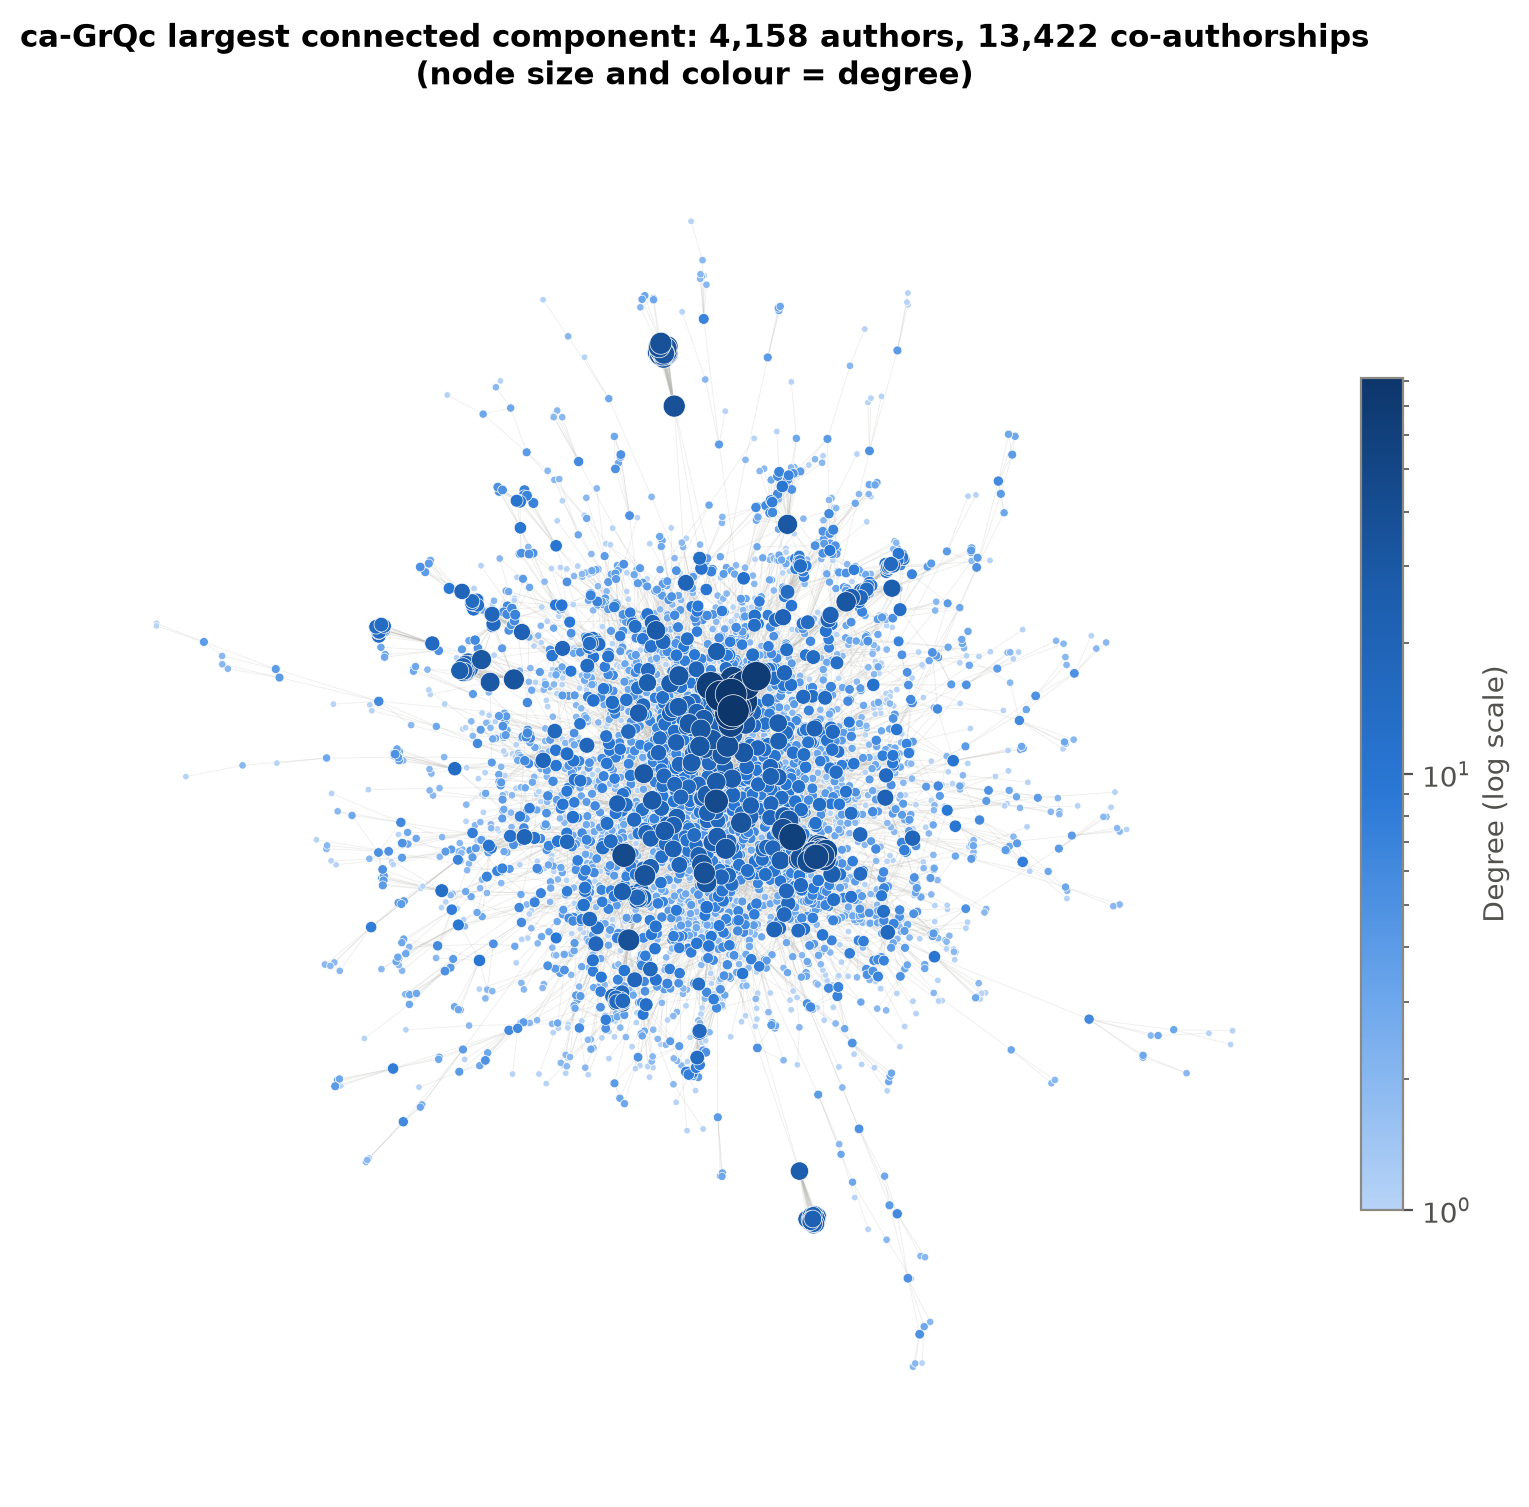

In [19]:
t = time.time()
pos = viz.lcc_layout(L)
print(f"LCC layout ready in {time.time() - t:.1f} s")
viz.save_fig(viz.plot_network_overview(L, pos), "fig_network_overview")
display(Image(VIZ_DIR / "fig_network_overview.png", width=700))

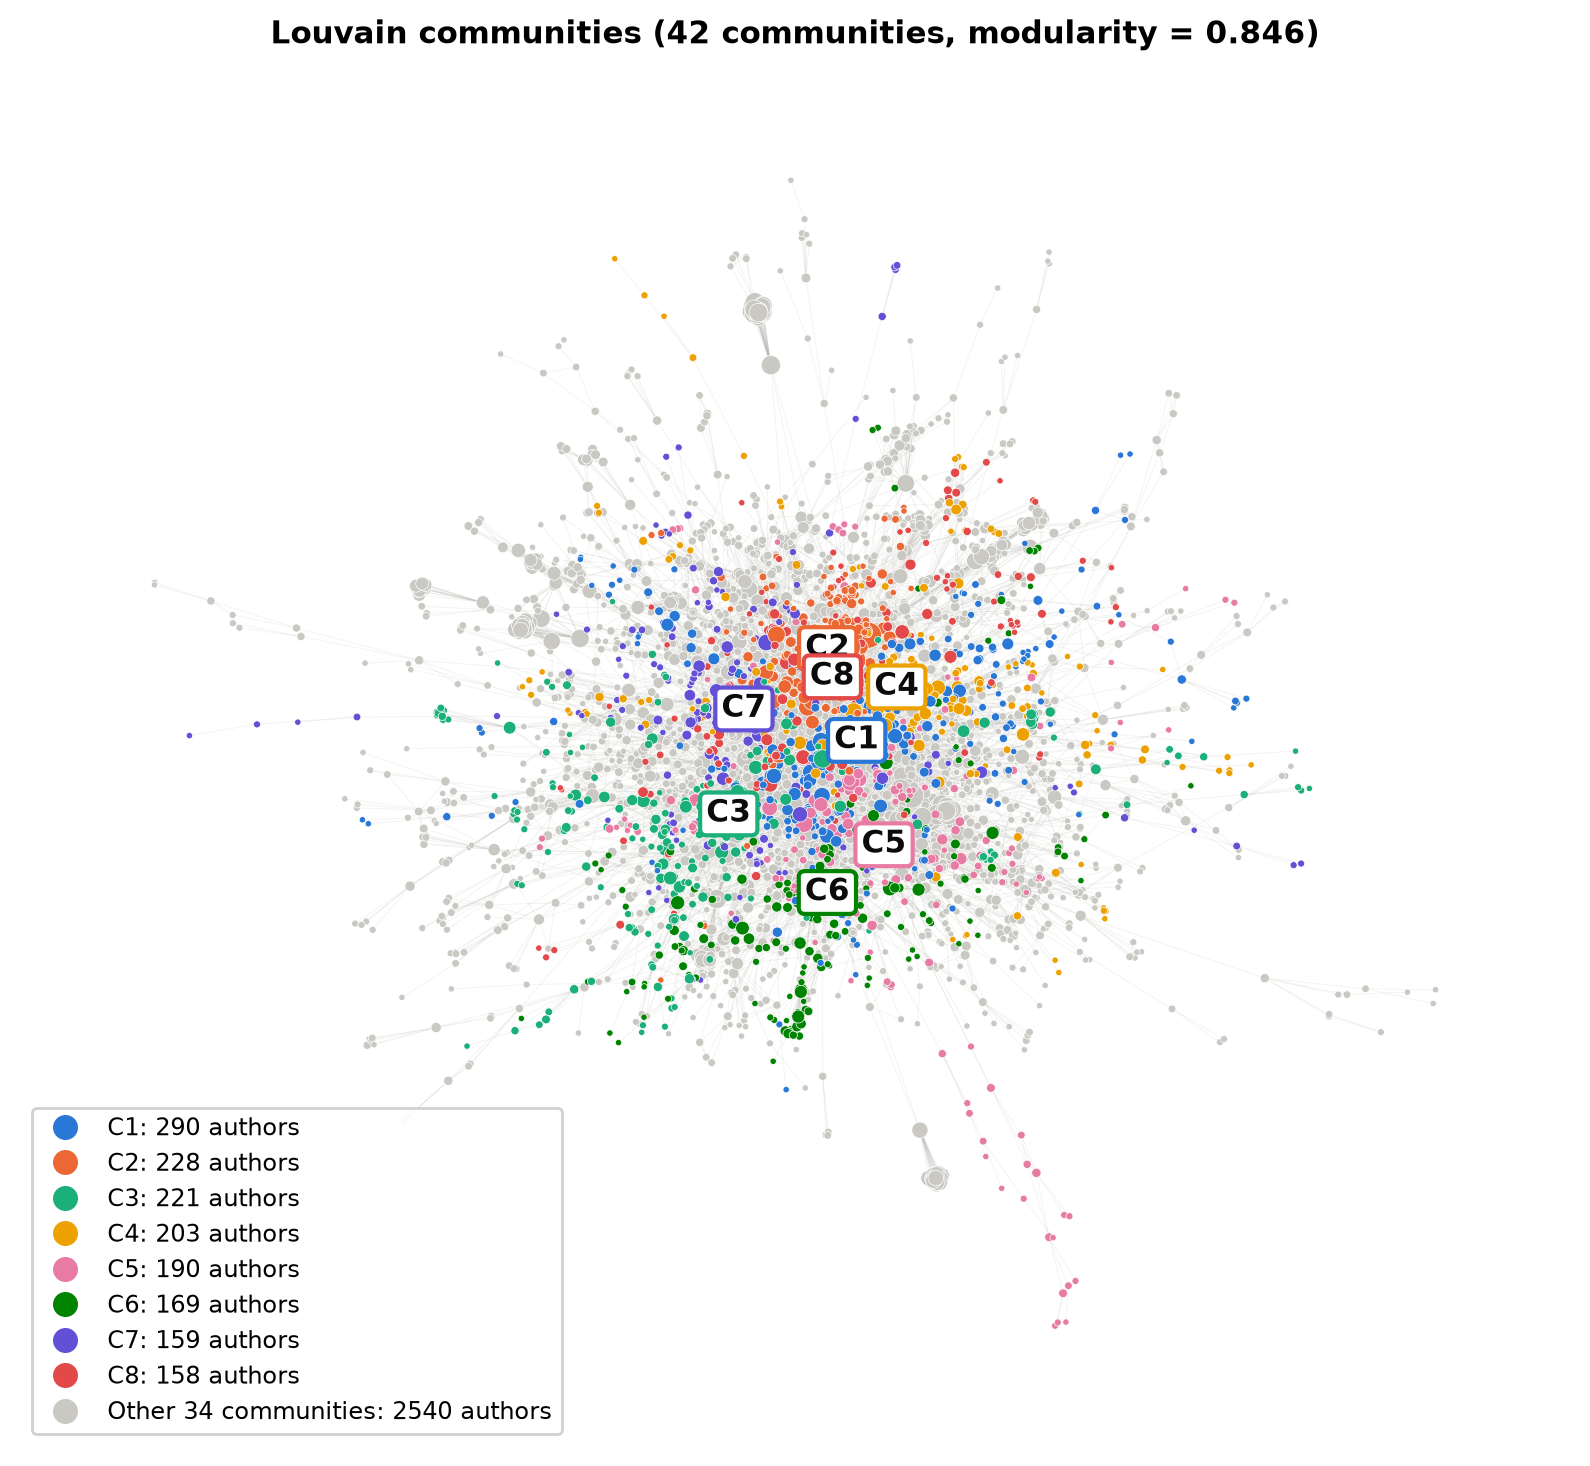

42 communities, modularity 0.846; 88.6% of held-out test edges fall inside a single community


In [20]:
communities = nx.community.louvain_communities(L, seed=SEED)
communities = sorted(communities, key=len, reverse=True)
community_of = {n: i + 1 for i, c in enumerate(communities) for n in c}
modularity = nx.community.modularity(L, communities)
RESULTS["communities"] = {"algorithm": "Louvain (networkx, seed 42)", "count": len(communities),
                          "modularity": modularity, "sizes_top10": [len(c) for c in communities[:10]],
                          "largest_share": len(communities[0]) / L.number_of_nodes()}
# How many test edges stay inside one community? (explains why local indices work)
intra = np.mean([community_of[u] == community_of[v] for u, v in split["test_pos"]])
RESULTS["communities"]["test_edges_intra_community"] = intra
viz.save_fig(viz.plot_communities(L, pos, communities), "fig_communities")
display(Image(VIZ_DIR / "fig_communities.png", width=700))
print(f"{len(communities)} communities, modularity {modularity:.3f}; "
      f"{intra:.1%} of held-out test edges fall inside a single community")

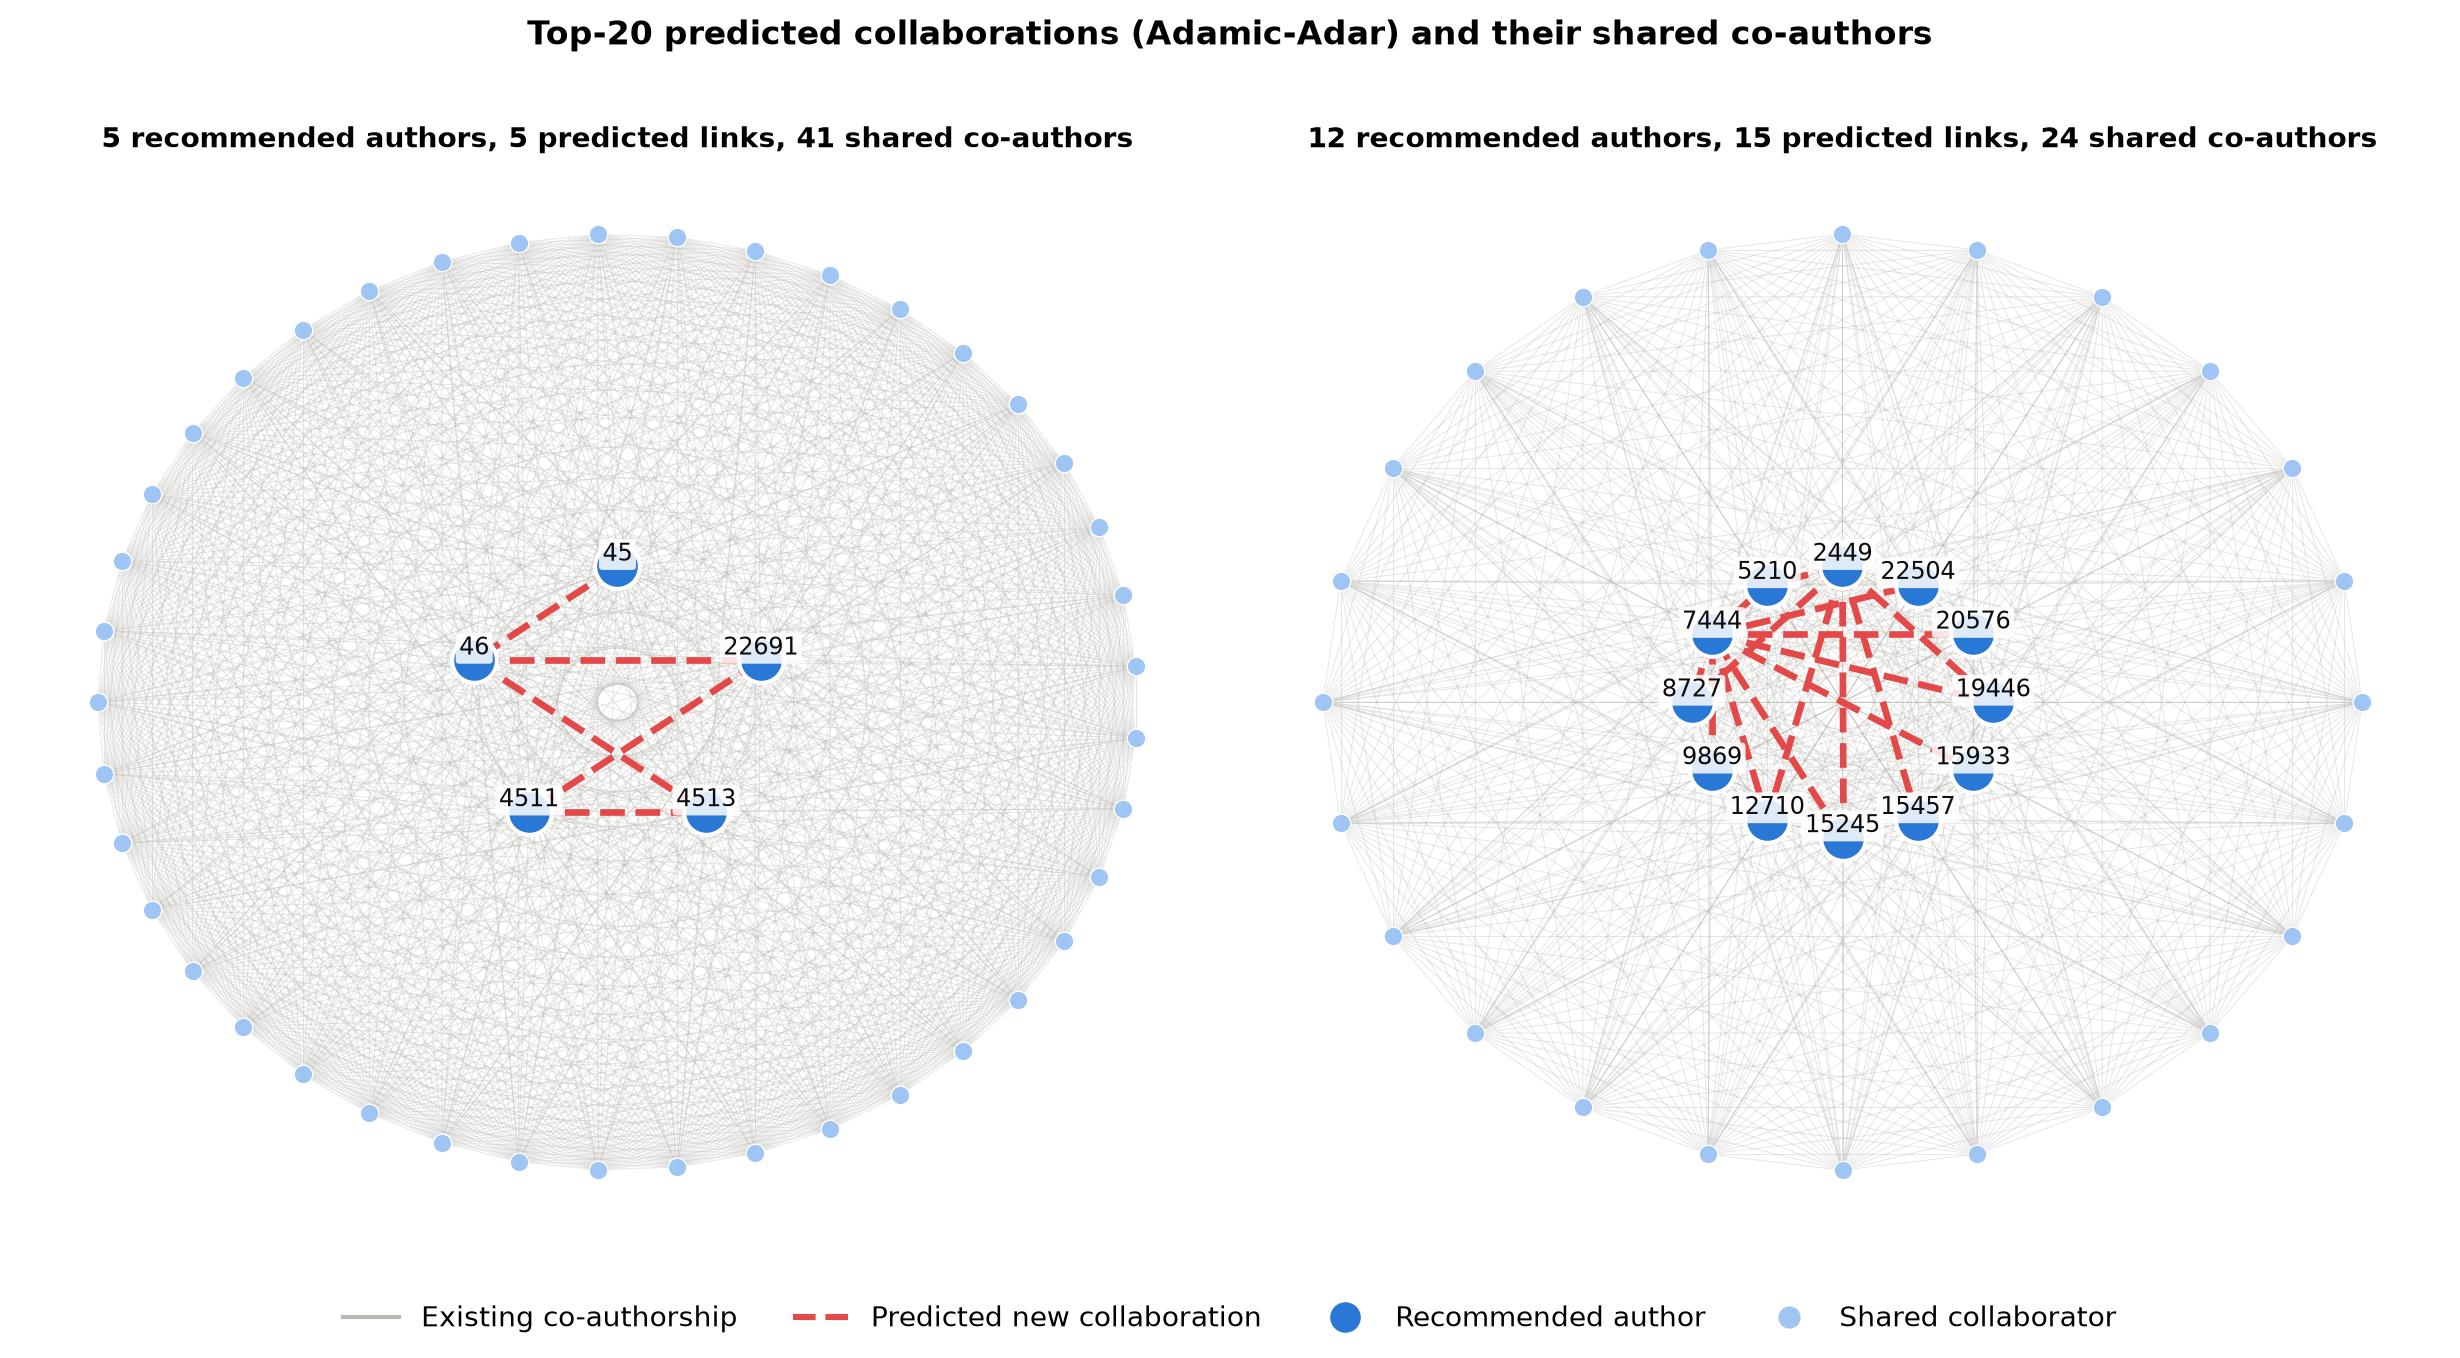

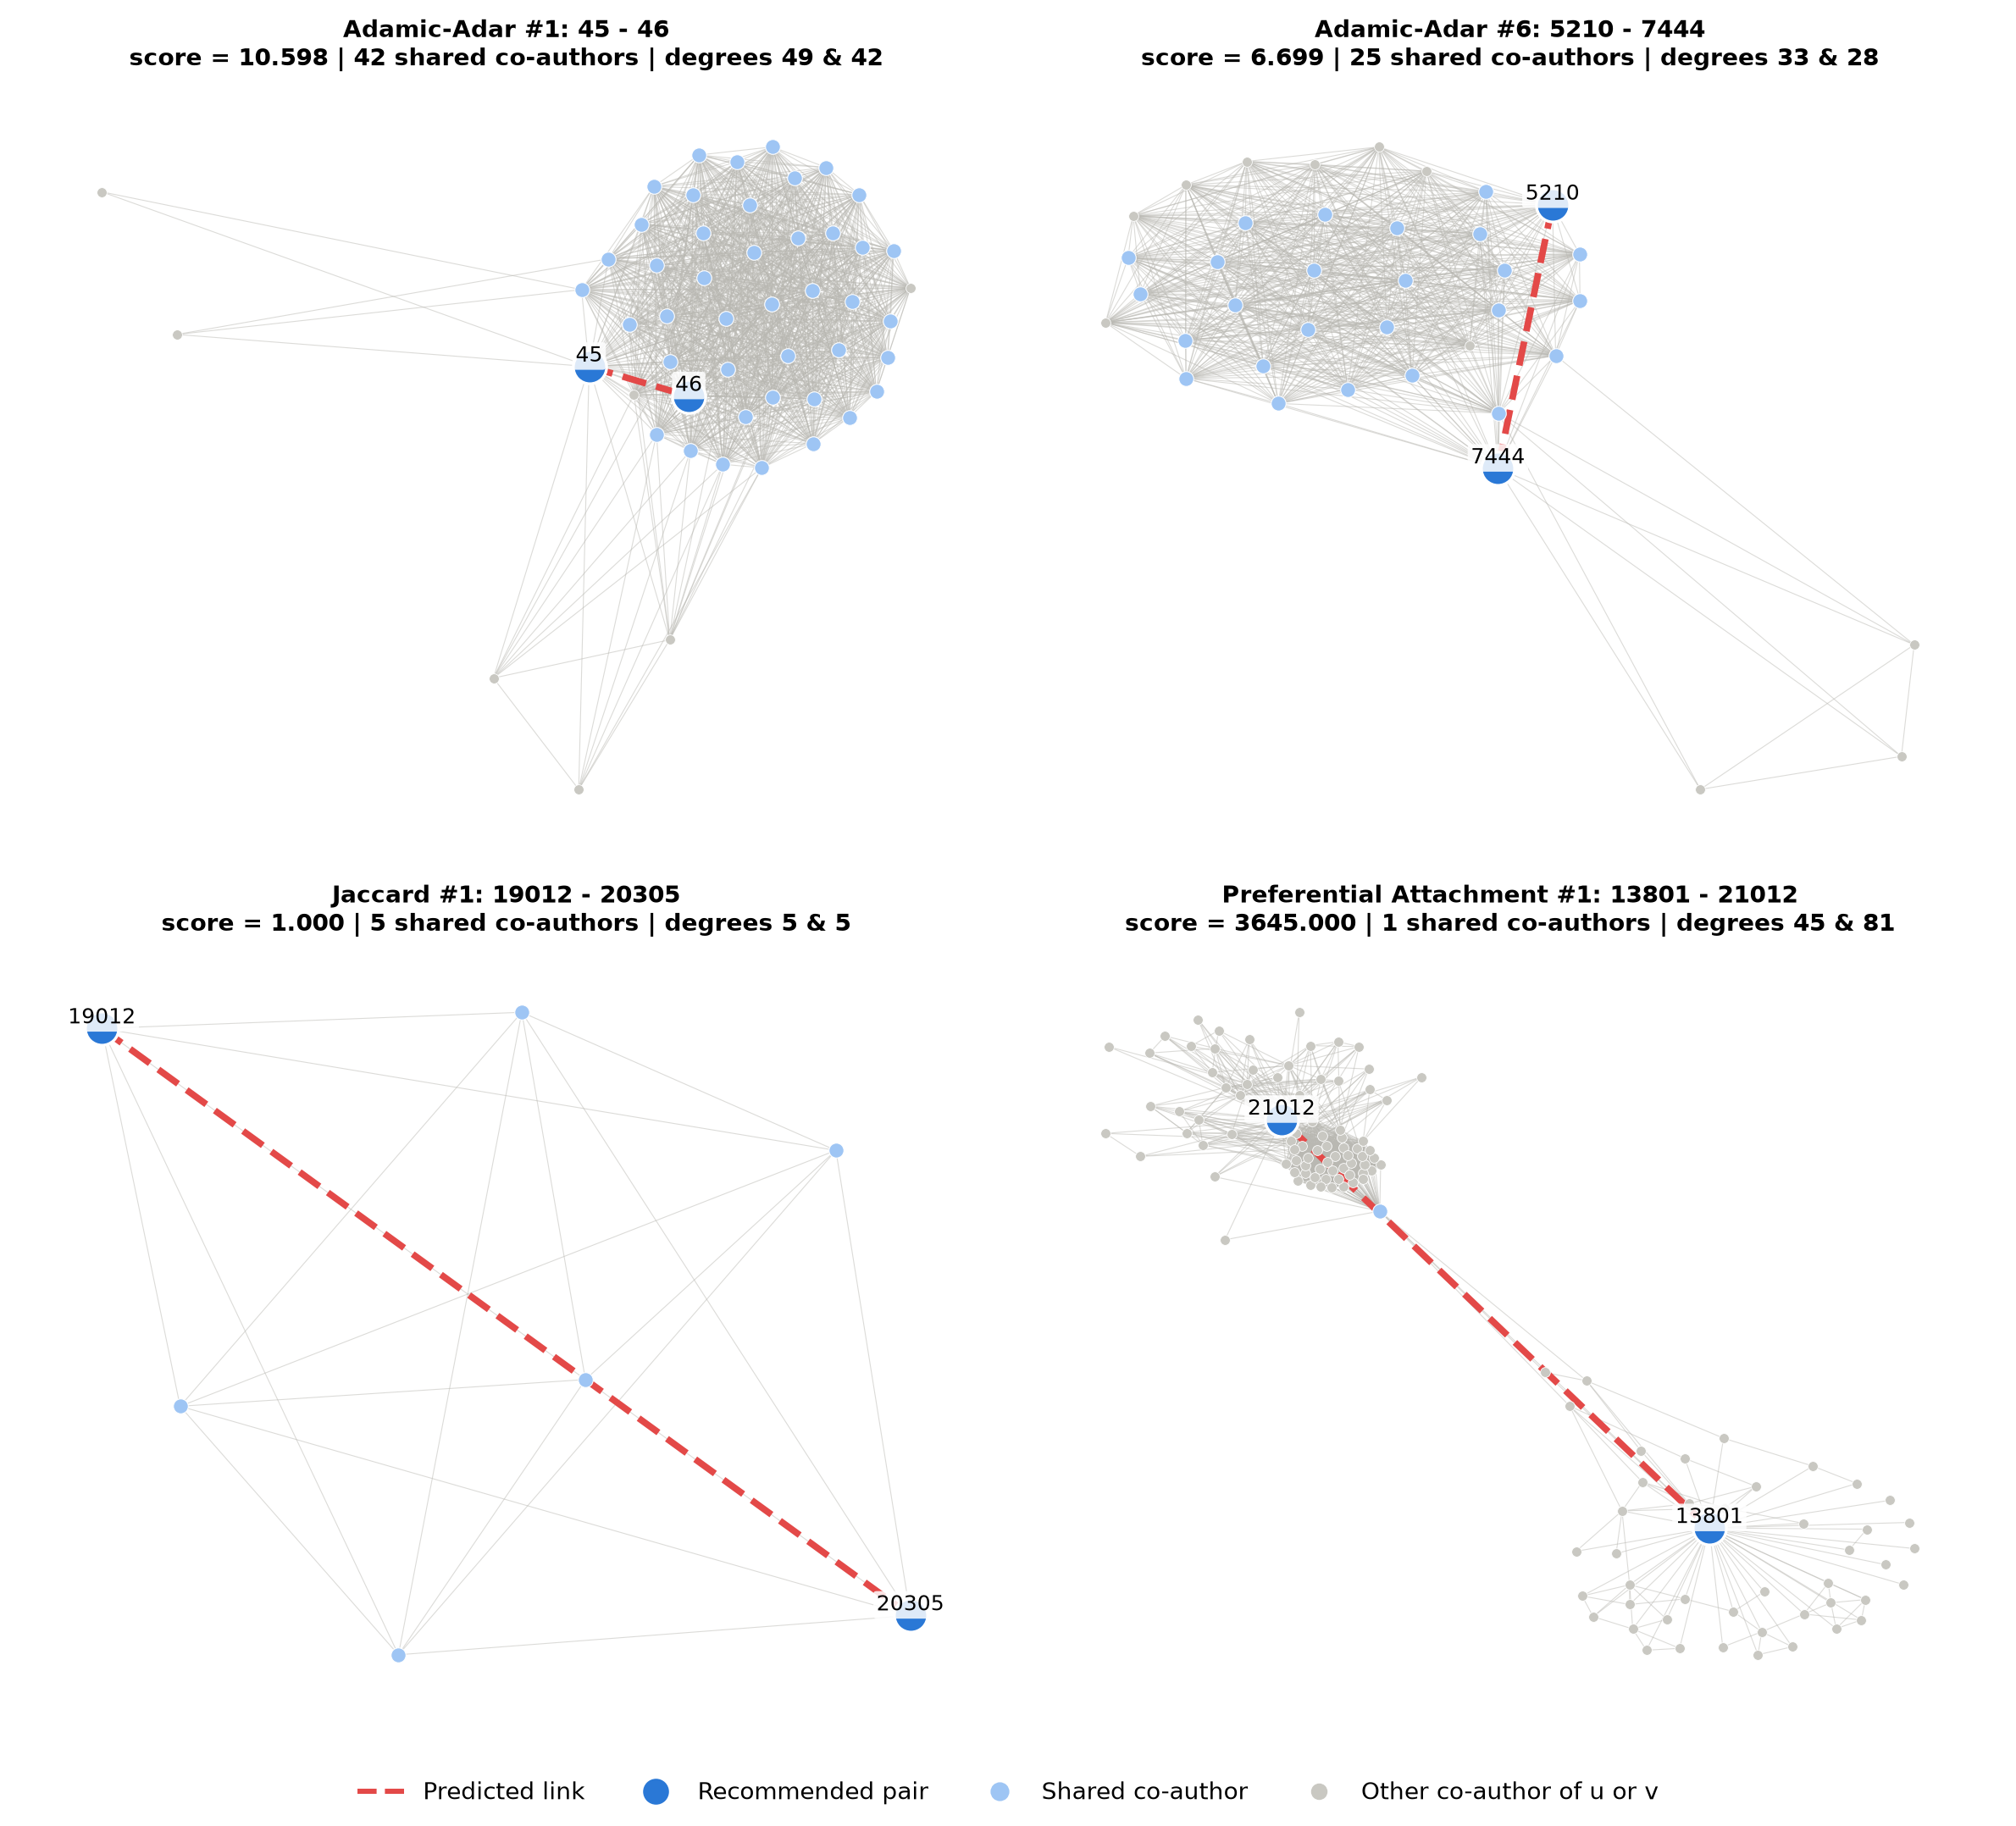

In [21]:
# Recommendation subgraph: top-20 pairs + shared collaborators; predicted links dashed red
H = viz.recommendation_subgraph(L, top20)
RESULTS["recommendation_subgraph"] = {"nodes": H.number_of_nodes(), "edges": H.number_of_edges()}
viz.save_fig(viz.plot_recommendation_subgraph(
    H, f"Top-20 predicted collaborations ({METHODS[best]}) and their shared co-authors"),
    "fig_recommendation_subgraph")
# Small multiples: the #1 pair of every method, plus the best method's first pair from a
# different collaboration group (many of its top pairs come from the same dense group)
grp = lambda r: {r.author_u, r.author_v} | (nbrs_full[r.author_u] & nbrs_full[r.author_v])
first = top20.iloc[0]
second = next(r for _, r in top20.iterrows()
              if len(grp(r) & grp(first)) / len(grp(r) | grp(first)) <= 0.5)
panel_rows = [first, second] + [top10[top10.method == METHODS[m]].iloc[0] for m in METHODS if m != best]
panels = pd.DataFrame(panel_rows).drop_duplicates(["author_u", "author_v"]).reset_index(drop=True)
viz.save_fig(viz.plot_recommendation_pairs(L, panels, cols=2), "fig_recommendation_pairs")
RESULTS["recommendation_pairs_shown"] = panels[["method", "rank", "author_u", "author_v"]].to_dict("records")
viz.interactive_recommendations(H, VIZ_DIR / "recommendation_subgraph_interactive.html",
                                f"Top-20 predicted collaborations ({METHODS[best]}) - dashed red = predicted")
display(Image(VIZ_DIR / "fig_recommendation_subgraph.png", width=750))
display(Image(VIZ_DIR / "fig_recommendation_pairs.png", width=850))

In [22]:
# Cytoscape export (GraphML + CSV tables with degree, community, PageRank, betweenness)
node_attrs = cent[cent.node.isin(set(L.nodes()))][["node", "degree", "pagerank", "betweenness"]].copy()
node_attrs["community"] = node_attrs.node.map(community_of)
predicted_all = pd.concat([top20, top10[top10.method != METHODS[best]]], ignore_index=True)
cyto_paths = viz.export_cytoscape(L, node_attrs, predicted_all)
RESULTS["cytoscape_files"] = {k: str(p.relative_to(ROOT)).replace("\\", "/") for k, p in cyto_paths.items()}
sorted(p.name for p in CYTO_DIR.iterdir())

['CYTOSCAPE_GUIDE.md',
 'ca-GrQc_lcc.graphml',
 'ca-GrQc_lcc_with_predictions.graphml',
 'cytoscape_edges.csv',
 'cytoscape_nodes.csv',
 'predicted_links.csv']

In [23]:
# Formula images (used by the report and the slides)
viz.render_formulas(OUTPUT_DIR / "formulas")
RESULTS["figures"] = sorted(p.name for p in VIZ_DIR.iterdir() if p.is_file())
RESULTS["meta"]["runtime_seconds"] = time.time() - T0
common.save_json(RESULTS, RESULTS_JSON)
print(f"Saved {RESULTS_JSON.relative_to(ROOT)} with sections: {list(RESULTS)}")
print(f"Total runtime: {RESULTS['meta']['runtime_seconds']:.0f} s")

Saved outputs\results.json with sections: ['meta', 'cleaning', 'stats_full', 'stats_lcc', 'top10_authors', 'top10_overlap_all_three', 'split', 'dataset_files', 'cross_check_max_abs_diff', 'cross_check_pairs', 'test_score_means', 'test_zero_cn_fraction', 'metrics_test', 'metrics_hard_negatives', 'n_hard_negatives', 'multi_seed', 'best_method', 'phase4_summary_md', 'hit_rate', 'candidate_pool_train', 'candidate_pool_full', 'top20', 'top10', 'top10_overlap', 'top20_group_density', 'top20_summary', 'communities', 'recommendation_subgraph', 'recommendation_pairs_shown', 'cytoscape_files', 'figures']
Total runtime: 275 s


---
## Phase 7 - Deliverables
* `report/build_report.py` builds **report/report.pdf** and `presentation/build_slides.py` builds
  **presentation/slides.pptx** (+ PDF) - both read only `outputs/results.json`, the CSVs and the figures
  written by this notebook, so every number in them comes from this run.
* `build_all.py` (project root) executes this notebook and then builds the report, slides and dataset zip.